---
title: "Andrews' inhibition function: the two claims in his Summary, tested"
description: "Andrews (1968) puts Haldane's enzyme-inhibition function into a batch and a chemostat balance and states, in one sentence of his Summary, that in batch culture the primary effect of substrate inhibition is an increase in the lag time while in continuous culture it may result in process instability. The page tests both with his own printed constants, digitises nothing, reproduces his two stated batch times from a closed form and his six stated continuous-culture outcomes, proves the chemostat bistable from the sign of a Jacobian, root-finds the thresholds he does not print, and adds two results he did not have: a seeded feed that removes the fold, and a plug-flow fermenter, solved with pymrm, that has no bistability at all."
categories: [sec:J, struct:S1, tier:T0, data:tier1, phase:liquid]
date: 2026-08-14
---

# Andrews' inhibition function: the two claims in his Summary, tested

**Catalog ID:** `J4.2` · **Structures:** `S1` · **Tier:** T0

## Background

The source is on disk and was read in full, at its native resolution:

> **Andrews, J. F.**, *A Mathematical Model for the Continuous Culture of
> Microorganisms Utilizing Inhibitory Substrates*, **Biotechnology and
> Bioengineering 10**(6), 707-723 (1968), doi:`10.1002/bit.260100602`.

Identity confirmed from the document's own first page: the masthead
*"BIOTECHNOLOGY AND BIOENGINEERING / VOL. X, PAGES 707-723 (1968)"*, the title,
the by-line *"JOHN F. ANDREWS, Environmental Systems Engineering, Clemson
University, Clemson, South Carolina 29631"* and the Summary, read on a 300 ppi
render. `pdfimages -list` reports every page of the file as CCITT-G4 bilevel at
300 ppi native, so rendering higher would be interpolation. All seventeen pages
were read at that resolution and every numeral quoted here was re-read on a crop
enlarged to digit scale.

**The paper prints no table.** A case-insensitive search of the extracted text
layer for `table` finds the word only inside *"unstable"*. There is no ruled
block, no column head and no `Table N` caption anywhere. What the paper prints is
**ten figures**, and **every parameter set is typeset inside a figure legend**.
Reading a typeset legend is transcription, not digitising.

**Nothing on this page is digitised.** No curve was traced, no marker detected,
no axis calibrated. The page therefore **does not establish empirical adequacy
against Andrews' plotted results**: where he prints a number in running text it
is reproduced, and where a claim lives only in a plotted curve it is out of
scope and is left there.

Two things read *inside* figures are on the transcription side of that line, and
both are named where they are used. Fig. 7 carries a typeset **annotation**,
`S_i ADDED IN INCREMENTS OF 2.0 GM/L`, which is text; it settles a sentence of
Andrews' running prose and it is in the CSV. And section 6 notes that both of
Fig. 9's $S_1$ curves **start at the origin**, which corroborates an initial
condition Andrews never prints. No axis was calibrated, no point was extracted,
**no number on this page comes from it**, and the effect of the assumption it
corroborates is reported anyway.

### The one sentence this page is about

Andrews' Summary, book p. 707, for the part that matters:

> *"Simulation studies show that the primary result of inhibition by substrate
> in a batch culture is an increase in the lag time whereas in continuous
> culture inhibition by substrate may result in process instability."*

Two claims, one sentence, and they are not the same kind of claim. He restates
them on book p. 715 and adds the reason they differ:

> *"The primary result of inhibition by substrate in a batch culture is an
> increase in the lag time. However, in the absence of organism death, the
> substrate will eventually be metabolized. Such is not the case in continuous
> cultures where high concentrations of inhibitory substrates may result in
> process instability with 'washout' of the organisms."*

**The batch claim is testable and not tautological, because the model has no lag
phase in it.** Book p. 711: *"the model has been kept as simple as possible by
assuming that there is no lag phase, organism death, endogenous respiration,
substrate used for maintenance energy, or inhibition by products."* Whatever lag
appears is produced by the kinetics, and can be measured against a
no-inhibition control.

**The continuous claim is analytic and needs no figure.** It is a statement about
how many steady states the chemostat has and which of them are stable, and both
are settled by root-finding and a 2x2 Jacobian.

### What J4.1 left here deliberately

`pages/J4.1-monod/` transcribed two substrate-inhibition rows into its
`data/printed-growth-laws.csv` and left them to this page:

| key | as printed | its flag |
|---|---|---|
| `froment_inhibition` | `r = r_m C_A / (K_S + C_A + C_A^2/K_i)` | *"OUT OF SCOPE - belongs to J4.2 (Andrews/Haldane); transcribed only so the scope boundary is checkable"* |
| `rawlings_substrate_inhibition` | `mu = mu_m S / (K_s + S + K_1 S^2)` | *"OUT OF SCOPE - J4.2"* |

This page **loads that CSV** rather than retyping either row, proves that both
are the same function as Andrews' eq. (1), and prints every quantity it shares
with J4.1 from J4.1's own rows. What J4.1 established about those rows, and
whether it affects this page, is in *The data*.

J4.1 recorded that Rawlings & Ekerdt cite their five growth laws to two
textbooks, *"not to Blackman, Tessier, Moser or Contois personally, and nothing
here is attributed to those four"*. Andrews' reference list carries the primary citations for
three of those four: Moser (Carnegie Inst. of Washington, 1958), **Teissier**
(*Ann. Physiol. Physicochim. Biol.* **12**, 527, 1936; Rawlings spells the law
"Tessier", and neither spelling is repaired here) and Contois (*J. Gen.
Microbiol.* **21**, 40, 1959). They are transcribed into this page's CSV for
whoever builds those cases; **none of them is on disk and none was consulted**,
and nothing on this page is attributed to any of them.

### What is *not* claimed here

- **Andrews' numbers are simulation output, not measurement.** His own p. 708:
  *"The solutions presented in this paper were obtained using PACTOLUS on the
  IBM 360 computer."* Reproducing them is **reproduction**, not validation, and
  the two stated times he quotes were read off his own plotted curves (*"It can
  be seen that only 12.5 hr are required..."*), so they carry his reading
  precision, not his solver's.
- **The paper contains no experimental data.** The only measurements it refers
  to are other people's, in prose and without numbers. So this page fits
  nothing, and no number on it is a goodness of fit.
- **Haldane (1930), Dixon & Webb (1964), Monod (1942), Moser (1958), Teissier
  (1936), Contois (1959), Koga & Humphrey (1967) and Brennan's PACTOLUS report
  are cited by Andrews and are not on disk.** None was consulted. Nothing is
  attributed to any of them beyond what Andrews prints.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.7"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "J4.2-andrews-substrate-inhibition"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults (numpy, scipy, pandas,
# matplotlib, pyyaml) are installed here with subprocess, not %pip.
from functools import lru_cache

import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import observed_orders
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (NEWTON_TOL, ChemostatMarch, PlugFlowFermenter, acclimate,
                   batch_ivp, batch_state, chemostat_ivp, count_seeded, dmu_dS,
                   fate, fold_point, half_rate_roots, jacobian, lag_share, lag_split,
                   mu, mu_eq1, mu_monod, one_root, seeded_steady_states,
                   separatrix_X_at, steady_states, t_batch)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5, "axes.grid": True,
                     "grid.alpha": 0.3})
# Okabe-Ito, assigned in fixed order and never cycled
C_BLUE, C_ORANGE, C_GREEN = "#0072B2", "#D55E00", "#009E73"
C_PURPLE, C_YELLOW, C_GREY = "#CC79A7", "#E69F00", "0.45"
claims = Claims(PAGE.split("-")[0])


def pct(x, d=4):
    """A fraction written as a signed percentage, for the computed prose."""
    return f"{100 * x:+.{d}f} %"

## The published model

Every equation below is transcribed from a 300 ppi render of the page that
prints it, and every one is in `data/andrews1968-printed-model.csv` with its
book page. The notebook reads the transcriptions out of that file; it does not
retype them.

**The inhibition function**, eq. (1), book p. 708:

$$\mu = \frac{\hat\mu}{1 + K_s/S + S/K_i} \tag{1}$$

and eq. (6), book p. 711, which Andrews says he actually computed with
(*"In developing the block diagram it was more convenient to use the inhibition
function in the form"*):

$$\mu = \hat\mu\left[\frac{S}{S^2/K_i + S + K_s}\right] \tag{6}$$

These are the same function. They are **not** the same numerically at $S = 0$,
which is where every batch and every startup simulation in the paper begins, and
eq. (6) is the one that is finite there.

**The maximum attainable rate and where it sits**, eqs. (2) and (3), book p. 709,
obtained by Andrews *"by setting the first derivative of eq. (1) equal to zero"*:

$$\hat\mu_m = \frac{\hat\mu}{1 + 2(K_s/K_i)^{0.5}} \qquad (2) \qquad\qquad
  S_m = (K_s K_i)^{0.5} \qquad (3)$$

**Batch culture**, eqs. (4) and (5), book p. 711:

$$\frac{dX}{dt} = \mu(S)\,X \qquad (4) \qquad\qquad
  \frac{dS}{dt} = -\frac{1}{Y}\,\mu(S)\,X \qquad (5)$$

**Continuous culture**, eqs. (7) and (8), book p. 711, for a *"complete mixing,
continuous-flow reactor"*:

$$\frac{dX_1}{dt} = \frac{X_0}{\theta} - \frac{X_1}{\theta} + \mu(S_1)\,X_1
  \qquad (7)$$

$$\frac{dS_1}{dt} = \frac{S_0}{\theta} - \frac{S_1}{\theta}
  - \frac{1}{Y}\,\mu(S_1)\,X_1 \qquad (8)$$

**Steady states**, eqs. (9) and (10), book p. 712:

$$S_1 = \frac{K_i(\hat\mu\theta - 1) + \left[(K_i)^2(\hat\mu\theta - 1)^2
        - 4K_sK_i\right]^{0.5}}{2} \qquad (9) \qquad\qquad
  X_i = Y(S_0 - S_1) \qquad (10)$$

**Washout residence time**, eq. (11), book p. 713:

$$\theta_w = \frac{1}{\hat\mu}\left[1 + 2(K_s/K_i)^{0.5}\right] \qquad (11)$$

### Three things about those printed equations

**eq. (9) is printed with a bare `+`, not `±`.** Read at digit scale on a
300 ppi crop. The quadratic it solves has two roots and Andrews' own running
text one paragraph later says so (*"Two values of substrate and organism
concentration are possible for each residence time since the substrate equation
is a quadratic"*). The root eq. (9) as printed returns is therefore the
**higher** one, which this same paper calls unstable. Reported, **not
repaired**: this page root-finds both roots independently and checks eq. (9)
against the upper one.

**eq. (10) is printed `X_i = Y(S_0 - S_1)`.** The effluent organism concentration
is $X_1$ in eq. (7), in the symbol list on the same page and in Fig. 8's curve
labels; $X_i$ is this paper's symbol for the **initial inoculum** (p. 713, *"The
initial innoculum $(X_i)$ has been chosen as 0.005 g/l"*, and Fig. 9's curve
key). A subscript defect, read at digit scale. Reported, **not repaired**; the
page writes $X_1 = Y(S_0 - S_1)$. The text layer of this scan turns `X_1` into
`XI`, so the text layer could never have shown it.

**One nuance on that defect.** On book p. 719 Andrews writes *"two different
values of initial organism concentration $(X_1)$"* and three lines later *"The
process fails when $X_i = 0.10$ g/l"*: both symbols for the inoculum, on one
page, read at digit scale (the first subscript an upright `1`, the second a
dotted italic `i`). The quantity eq. (10) defines is the *effluent*
concentration whatever he calls the inoculum, so the finding stands, but it
rests on the symbol list and eq. (7), not on a convention the paper keeps
perfectly.

**eq. (11) is exactly $1/\hat\mu_m$.** Not stated in the paper. It is the
residence time at which the discriminant of eq. (9) vanishes and the two steady
states merge, a fold. The two are the same arithmetic expression, and section 4
shows that a fold is only **one** of the two ways this chemostat washes out.

### What $K_s$ and $K_i$ actually are

Andrews defines them on book p. 709 as half-rate concentrations: $K_s$
*"numerically equals lowest concentration of substrate at which the specific
growth rate is equal to one-half the maximum specific growth rate in the absence
of inhibition"*, and $K_i$ *"the highest"* such concentration. Set eq. (1) equal
to $\hat\mu/2$ and the two roots are

$$S_\pm = \tfrac12 K_i\left(1 \pm \sqrt{1 - 4K_s/K_i}\right),$$

so the definitions are exact only as $K_s/K_i \to 0$, and they have **no
solution at all** unless $K_i \ge 4K_s$, which is exactly the condition under
which his own eq. (2) gives $\hat\mu_m \ge \hat\mu/2$. How far out they are
depends on which of his three printed $K_i$ you take, and the parameter cell
below prints all three. This is **not** filed as a printed defect: it is an
approximation, not a misprint, and the nearest thing in the paper to a
qualification is on the same page, *"even when $K_s$ and $K_i$ are well
separated there is a considerable reduction in the maximum specific growth rate
attainable"*. The page supplies the numbers and the exact condition and does
**not** claim Andrews was unaware.

In [3]:
# --------------------------------------------------------- the transcriptions
PRN = load_data("andrews1968-printed-model.csv", page=PAGE).set_index("key")
PMETA = load_meta("andrews1968-printed-model.csv", page=PAGE)


def printed(key, field="as_printed"):
    """The verbatim transcription, looked up and never retyped in a cell."""
    return str(PRN.loc[key, field])


print(cite_data(PMETA))
print(f"{len(PRN)} transcribed rows, {int(PRN['flag'].notna().sum())} flagged\n")
for _k in ("eq1", "eq6", "eq2", "eq3", "eq9", "eq10", "eq11"):
    print(f"eq. ({_k[2:]})".ljust(9), f"p.{PRN.loc[_k, 'page']} :  {printed(_k)}")

Andrews, J. F. (1968) — "A Mathematical Model for the Continuous Culture of Microorganisms Utilizing Inhibitory Substrates", Biotechnology and Bioengineering 10(6) 707-723 (1968), Environmental Systems Engineering, Clemson University
 — doi:10.1002/bit.260100602 — transcription
51 transcribed rows, 40 flagged

eq. (1)   p.708 :  mu = muhat / (1 + K_s/S + S/K_i)
eq. (6)   p.711 :  mu = muhat [ S / ( (S)^2/K_i + S + K_s ) ]
eq. (2)   p.709 :  muhat_m = muhat / (1 + 2 (K_s/K_i)^0.5)
eq. (3)   p.709 :  S_m = (K_s K_i)^0.5
eq. (9)   p.712 :  S_1 = { K_i(muhat theta - 1) + [ (K_i)^2 (muhat theta - 1)^2 - 4 K_s K_i ]^0.5 } / 2
eq. (10)  p.712 :  X_i = Y(S_0 - S_1)
eq. (11)  p.713 :  theta_w = (1/muhat)[ 1 + 2 (K_s/K_i)^0.5 ]


## Parameters and assumptions

**Every constant used on this page is printed by Andrews, in a typeset figure
legend or in running text.** Nothing is fitted, nothing is inferred, nothing is
read off a curve. The legends were read at digit scale on 300 ppi crops; three
of the pages carrying them (Figs. 4, 7, 9) are landscape in the file and
`pdftoppm` returns them rotated, so those crops were rotated back before
reading. The cell below holds them in one dictionary `P0` that every function
takes, and prints them with the legends they come from.

**The `GM/L` on the yield in two legends (Figs. 4 and 7) is a printed defect,
reported and not repaired.** $Y$ is defined on book p. 711 as *"yield
coefficient, mass organisms produced/mass substrate utilized"*, i.e.
dimensionless, and eq. (5) requires it so: $dS/dt$ and $dX/dt$ have the same
units, so $Y$ cannot carry any. The constraint that decides it is that printed
definition together with the dimensions of eq. (5), not the count of legends
that print `GM/GM`. **The numeral is not in question, only the unit.**

**$X_0 = 0$ throughout, and that is this page's assumption, not Andrews'.** He
defines $X_0$ in eq. (7) and never gives it a value: a full-text search of the
extracted layer for `X0`, `X 0` and `influent`, plus a read of all seventeen
renders, finds no numeral for it and no legend carrying it. Sterile feed is the
only reading under which his Fig. 8-10 experiments make sense, because washout
is impossible when $X_0 > 0$. Section 7 computes what a non-zero $X_0$ does,
labelled as an extension.

**Two initial conditions are not printed either**, and the page says which
assumption it makes and how much the answer depends on it:

- **Fig. 9's $S_1(0)$.** Andrews says only that *"at time 0+ the reactor is
  abruptly converted from a batch reactor to a continuous-flow reactor"*. The
  page takes $S_1(0) = 0$, a batch that has finished, and reports the
  threshold's sensitivity over a sampled range of $S_1(0)$.
- **Fig. 10's initial state.** The page takes the stable steady state at
  Andrews' $S_0$ and $\theta$, the only state from which *"during
  continuous-flow operation"* makes sense.

**One sentence with three literal readings, settled by Andrews' own figure.**
Book p. 715 describes the acclimation procedure as *"a substrate concentration
of 2.0 g/l with the substrate concentration being increased in 2.0 g/l steps
after reduction in each case to 0.02 g/l"*. In isolation that supports three
readings: **reset** the substrate to 2.0 each cycle, **increment** it by 2.0
from the 0.02 g/l left at the end of the previous cycle, or step the *initial*
concentration up a **ladder** 2.0, 4.0, 6.0 g/l. They are not equivalent, and
section 2 prices all three. The typeset annotation inside Fig. 7, the figure
the p. 715 sentence is about, reads

> `REPEATED ORGANISM SEPARATION & DILUTION. S_i ADDED IN INCREMENTS OF 2.0 GM/L`

read at digit scale on a 300 ppi crop of the rotated landscape page and
transcribed into `data/andrews1968-printed-model.csv` as `fig7_annotation`.
*Added in increments of 2.0* is the increment reading: each cycle adds 2.0 g/l
of substrate to what is left. The ladder reading would add 2.0, then 4.0, then
6.0, not *increments of 2.0*, and is excluded. **The increment reading is the
one reported**; the reset reading is kept and priced as the near neighbour it
is, and the ladder reading is reported as the one the annotation rules out.

In [4]:
# ------------------------------------------------- Andrews' printed constants
P0 = dict(
    muh=1.0,      # muhat, HR^-1     Figs. 1, 4-10 legends
    Ks=0.03,      # K_s,   GM/L      Figs. 1, 4-10 legends
    Ki=2.0,       # K_i,   GM/L      Figs. 6-10 legends
    Y=0.5,        # Y,     GM/GM     Figs. 5, 6, 8, 9, 10 legends (GM/L in 4 and 7)
    theta=3.0,    # theta, HRS       Figs. 8, 9, 10 legends
    S0=5.0,       # S_0,   GM/L      Figs. 8, 9, 10 legends
    Si=10.0,      # S_i,   GM/L      Figs. 5, 6 legends and p. 715
    Xi=0.005,     # X_i,   GM/L      Figs. 5, 7 legends and p. 713
    X0=0.0,       # X_0,   never printed: sterile feed is this page's assumption
)
MU_HAT, K_S, K_I, YIELD = P0["muh"], P0["Ks"], P0["Ki"], P0["Y"]
THETA, S_FEED, S_INIT, X_INIT = P0["theta"], P0["S0"], P0["Si"], P0["Xi"]
X_TARGET = 5.0                  # g/l, the biomass of Andrews' p. 715 sentence
T_DIRECT_PRINTED, T_SEED_PRINTED = 36.0, 12.5   # hr, p. 715, his readings of Fig. 7
KI_FIG4, KI_FIG1 = 1.0, 0.50    # GM/L, the other two K_i he prints (Figs. 4, 1)


def with_(**kw):
    """Andrews' constants with some replaced (the break table's defects)."""
    return dict(P0, **kw)


_rows = [("$\\hat\\mu$", MU_HAT, "HR$^{-1}$", "Figs. 1, 4-10"),
         ("$K_s$", K_S, "GM/L", "Figs. 1, 4-10"),
         ("$K_i$", K_I, "GM/L", "Figs. 6-10 (also {:g} in Fig. 4, {:.2f} in Fig. 1)"
          .format(KI_FIG4, KI_FIG1)),
         ("$Y$", YIELD, "GM/GM (GM/L in Figs. 4, 7)", "Figs. 4-10"),
         ("$\\theta$", THETA, "HRS", "Figs. 8, 9, 10"),
         ("$S_0$", S_FEED, "GM/L", "Figs. 8, 9, 10"),
         ("$S_i$", S_INIT, "GM/L", "Figs. 5, 6 and p. 715"),
         ("$X_i$", X_INIT, "GM/L", "Figs. 5, 7 and p. 713"),
         ("$X_0$", P0["X0"], "never printed", "this page's assumption")]
display(Markdown("| symbol | value | units as printed | where |\n|---|---|---|---|\n"
                 + "\n".join(f"| {s} | {v:g} | {u} | {w} |" for s, v, u, w in _rows)))

# ---------------- eq. (1) == eq. (6), and eqs. (2), (3) re-derived, in sympy
_S, _Ks, _Ki, _mh = sp.symbols("S K_s K_i muhat", positive=True)
EQ1_EQ6_RESID = sp.simplify(_mh/(1 + _Ks/_S + _S/_Ki) - _mh*_S/(_S**2/_Ki + _S + _Ks))
_dmu = sp.diff(_mh*_S/(_S**2/_Ki + _S + _Ks), _S)
_Sm_sym = [s for s in sp.solve(sp.numer(sp.together(_dmu)), _S) if s.is_positive][0]
EQ3_RESID = sp.simplify(_Sm_sym - sp.sqrt(_Ks*_Ki))
EQ2_RESID = sp.simplify(sp.simplify((_mh*_S/(_S**2/_Ki + _S + _Ks)).subs(_S, _Sm_sym))
                        - _mh/(1 + 2*sp.sqrt(_Ks/_Ki)))
for _name, _r in (("eq.(1) - eq.(6)", EQ1_EQ6_RESID), ("eq.(3) residual", EQ3_RESID),
                  ("eq.(2) residual", EQ2_RESID)):
    print(f"sympy  {_name:16s} = {_r}")
    if _r != 0:
        raise RuntimeError(f"sympy identity {_name} is not zero: {_r}")


def inhibition_study(P, eq2_factor=2.0, eq3_sqrt=True):
    """Eqs. (2), (3), (11) and the half-rate definitions at the constants P.

    eq2_factor and eq3_sqrt are transcriptions of eqs. (2), (11) and (3); the
    break table mis-transcribes them. The extremum is the single root of the
    analytic dmu/dS on 1e-8 to 1e8 g/l.
    """
    mum = P["muh"]/(1 + eq2_factor*np.sqrt(P["Ks"]/P["Ki"]))          # eq. (2)
    Sm = np.sqrt(P["Ks"]*P["Ki"]) if eq3_sqrt else P["Ks"]*P["Ki"]    # eq. (3)
    thw = (1/P["muh"])*(1 + eq2_factor*np.sqrt(P["Ks"]/P["Ki"]))      # eq. (11)
    Sm_root = one_root(lambda s: dmu_dS(s, P), 1e-8, 1e8, "argmax of mu", n_scan=33, xtol=1e-17)
    out = dict(mu_hat_m_eq2_per_h=mum, S_m_eq3_g_per_l=Sm, theta_washout_h=thw,
               eq2_vs_rootfound_max_rel=abs(mum/float(mu(Sm_root, P)) - 1),
               eq3_vs_rootfound_argmax_rel=abs(Sm/Sm_root - 1),
               eq11_minus_inverse_eq2=thw - 1.0/mum,
               rm_as_maximum_overstatement_rel=P["muh"]/mum - 1,
               Ki_min_for_half_rate_defs_g_per_l=4*P["Ks"], S_m_root=Sm_root)
    for Ki, tag in ((P["Ki"], ""), (KI_FIG4, "_Ki1"), (KI_FIG1, "_Ki0p5")):
        lo, hi = half_rate_roots(Ki, P["Ks"])
        out["half_rate_low" + tag], out["half_rate_high" + tag] = lo, hi
        out["Ks_definition_rel_error" + tag] = (lo - P["Ks"])/P["Ks"]
        out["Ki_definition_rel_error" + tag] = (hi - Ki)/Ki
    out["half_rate_low_root_g_per_l"] = out["half_rate_low"]
    out["half_rate_high_root_g_per_l"] = out["half_rate_high"]
    return out


INH = inhibition_study(P0)
MU_HAT_M, S_M, THETA_W = INH["mu_hat_m_eq2_per_h"], INH["S_m_eq3_g_per_l"], INH["theta_washout_h"]
# the closed-form half-rate roots against a root-find of eq. (6) = muhat/2 on each limb
_half = lambda s: float(mu(s, P0)) - MU_HAT/2          # noqa: E731
HALF_ROOTS_FOUND = (one_root(_half, 1e-9, S_M, "low half-rate root"),
                    one_root(_half, S_M, 1e4, "high half-rate root"))
HALF_ROOTS_REL = max(abs(HALF_ROOTS_FOUND[0]/INH["half_rate_low"] - 1),
                     abs(HALF_ROOTS_FOUND[1]/INH["half_rate_high"] - 1))
if HALF_ROOTS_REL > 1e-12:
    raise RuntimeError(f"half-rate closed form and root-find differ by {HALF_ROOTS_REL:.2e}")

claims.value("mu_hat_m_eq2_per_h", MU_HAT_M, unit="1/h")
claims.value("S_m_eq3_g_per_l", S_M, unit="g/l")
claims.value("theta_washout_h", THETA_W, unit="h")
claims.bound("eq2_vs_rootfound_max_rel", INH["eq2_vs_rootfound_max_rel"], max=1e-12,
             basis="tolerance", note="eq. (2) against mu at the root of the analytic dmu/dS "
             "(xtol 1e-17): a transcription check, equal by algebra")
claims.bound("eq3_vs_rootfound_argmax_rel", INH["eq3_vs_rootfound_argmax_rel"], max=1e-12,
             basis="tolerance", note="eq. (3) against the root of the analytic dmu/dS")
claims.bound("eq11_minus_inverse_eq2", abs(INH["eq11_minus_inverse_eq2"]), max=1e-15,
             basis="identity", structural=True, unit="h",
             note="eq. (11) and 1/eq. (2) are the same arithmetic expression")
claims.value("rm_as_maximum_overstatement_rel", INH["rm_as_maximum_overstatement_rel"])
claims.value("Ki_min_for_half_rate_defs_g_per_l", INH["Ki_min_for_half_rate_defs_g_per_l"],
             unit="g/l")
claims.value("half_rate_low_root_g_per_l", INH["half_rate_low_root_g_per_l"], unit="g/l")
claims.value("half_rate_high_root_g_per_l", INH["half_rate_high_root_g_per_l"], unit="g/l")
for _tag in ("", "_Ki1", "_Ki0p5"):
    claims.value("Ks_definition_rel_error" + _tag, INH["Ks_definition_rel_error" + _tag])
    claims.value("Ki_definition_rel_error" + _tag, INH["Ki_definition_rel_error" + _tag])

_tab = "\n".join(
    f"| {Ki:.2f} | {where} | {INH['half_rate_low' + tag]:.7f} | {INH['half_rate_high' + tag]:.7f} "
    f"| {pct(INH['Ks_definition_rel_error' + tag])} | {pct(INH['Ki_definition_rel_error' + tag])} |"
    for Ki, where, tag in ((K_I, "Figs. 6-10, this page's case", ""), (KI_FIG4, "Fig. 4", "_Ki1"),
                           (KI_FIG1, "Fig. 1", "_Ki0p5")))
display(Markdown(
    f"eq. (2) gives $\\hat\\mu_m$ = {MU_HAT_M:.6f} h$^{{-1}}$ and eq. (3) $S_m$ = {S_M:.6f} g/l; "
    f"both agree with the root of the analytic $d\\mu/dS$ to within "
    f"{max(INH['eq2_vs_rootfound_max_rel'], INH['eq3_vs_rootfound_argmax_rel']):.0e} relative "
    f"(bound 1e-12), and eq. (11) gives $\\theta_w$ = {THETA_W:.6f} h, equal to $1/\\hat\\mu_m$. "
    "The half-rate roots of eq. (1) at Andrews' three printed $K_i$:\n\n"
    "| $K_i$ (g/l) | where | low root (g/l) | high root (g/l) | low vs $K_s$ | high vs $K_i$ |\n"
    "|---|---|---|---|---|---|\n" + _tab +
    f"\n\nThe approximation is mildest at the $K_i$ this page uses; at his Fig. 1 the "
    f"$K_s$ error is {INH['Ks_definition_rel_error_Ki0p5']/INH['Ks_definition_rel_error']:.1f} "
    f"times larger, so quoting only the mildest row would understate it. The definitions "
    f"have a solution only for $K_i \\ge 4K_s$ = {INH['Ki_min_for_half_rate_defs_g_per_l']:g} g/l."))

# eq. (1) at S = 0 is the reason Andrews rewrote it as eq. (6)
_Sg = np.geomspace(1e-6, 100, 4001)
print(f"eq.(1) at S=0 : {float(mu_eq1(0.0, P0))!r}      eq.(6) at S=0 : {float(mu(0.0, P0))!r}")
print(f"eq.(1) vs eq.(6), max |rel| over S in [1e-6, 100]: "
      f"{np.max(np.abs(mu_eq1(_Sg, P0)/mu(_Sg, P0) - 1)):.1e}")

| symbol | value | units as printed | where |
|---|---|---|---|
| $\hat\mu$ | 1 | HR$^{-1}$ | Figs. 1, 4-10 |
| $K_s$ | 0.03 | GM/L | Figs. 1, 4-10 |
| $K_i$ | 2 | GM/L | Figs. 6-10 (also 1 in Fig. 4, 0.50 in Fig. 1) |
| $Y$ | 0.5 | GM/GM (GM/L in Figs. 4, 7) | Figs. 4-10 |
| $\theta$ | 3 | HRS | Figs. 8, 9, 10 |
| $S_0$ | 5 | GM/L | Figs. 8, 9, 10 |
| $S_i$ | 10 | GM/L | Figs. 5, 6 and p. 715 |
| $X_i$ | 0.005 | GM/L | Figs. 5, 7 and p. 713 |
| $X_0$ | 0 | never printed | this page's assumption |

sympy  eq.(1) - eq.(6)  = 0
sympy  eq.(3) residual  = 0
sympy  eq.(2) residual  = 0


eq. (2) gives $\hat\mu_m$ = 0.803246 h$^{-1}$ and eq. (3) $S_m$ = 0.244949 g/l; both agree with the root of the analytic $d\mu/dS$ to within 0e+00 relative (bound 1e-12), and eq. (11) gives $\theta_w$ = 1.244949 h, equal to $1/\hat\mu_m$. The half-rate roots of eq. (1) at Andrews' three printed $K_i$:

| $K_i$ (g/l) | where | low root (g/l) | high root (g/l) | low vs $K_s$ | high vs $K_i$ |
|---|---|---|---|---|---|
| 2.00 | Figs. 6-10, this page's case | 0.0304640 | 1.9695360 | +1.5468 % | -1.5232 % |
| 1.00 | Fig. 4 | 0.0309584 | 0.9690416 | +3.1947 % | -3.0958 % |
| 0.50 | Fig. 1 | 0.0320551 | 0.4679449 | +6.8502 % | -6.4110 % |

The approximation is mildest at the $K_i$ this page uses; at his Fig. 1 the $K_s$ error is 4.4 times larger, so quoting only the mildest row would understate it. The definitions have a solution only for $K_i \ge 4K_s$ = 0.12 g/l.

eq.(1) at S=0 : 0.0      eq.(6) at S=0 : 0.0
eq.(1) vs eq.(6), max |rel| over S in [1e-6, 100]: 4.4e-16


## The data

**There are no data.** Andrews reports no measurement of any kind; the only
experimental work he refers to is other people's, in prose and without numbers
(Boon and Laudelout on *Nitrobacter winogradskyi*, p. 708). So this page fits
nothing and no number on it is a goodness of fit. What it has instead is
**Andrews' own printed constants, his two stated numerical results and the six
stated outcomes of his three continuous-culture experiments**, and the question
is whether those stated results follow from his stated model.

`data/andrews1968-printed-model.csv` is the transcription: every equation, every
figure-legend parameter set and every claim this page uses, verbatim, with the
printed book page each came from and a flag on every row that carries a defect
or an oddity. Its sidecar records the negative claims above and how each was
checked.

### The one CSV borrowed from another page, and what that page found about it

This page loads `printed-growth-laws.csv` from `pages/J4.1-monod/`, six rows:
`froment_inhibition`, `rawlings_substrate_inhibition`, `froment_rm_definition`,
`froment_asymptote`, `rawlings_steady_states` and `rawlings_Dc`. Per `AGENTS.md`
that means reading J4.1's findings about those rows, and saying whether each
affects this page:

| J4.1's finding | affects this page? |
|---|---|
| `froment_inhibition` and `rawlings_substrate_inhibition` are flagged **"OUT OF SCOPE"** for J4.2, transcribed only so the scope boundary is checkable, and J4.1 does not evaluate them | **Yes, directly**: they are the two rows this page picks up. It evaluates them and proves both equal Andrews' eq. (1). |
| Froment's born-digital text layer loses operators in equations to Private-Use-Area glyphs (`U+F02D`, `U+F03D`, `U+F02B`), so J4.1 read its equations on renders | **No** for Andrews, a bilevel scan read on renders; it is why `froment_inhibition` can be trusted. |
| `froment_rm_definition`: *"r_m is the maximum specific rate of biomass growth"* | **Yes, and it is a trap.** That definition belongs to Froment's Monod eq. (1.5.2-1). Carried across to his inhibition eq. (1.5.2-4) it is false: the maximum of that function is $r_m/(1 + 2\sqrt{K_S/K_i})$, Andrews' eq. (2). The cell below quantifies the gap. |
| `froment_asymptote` says the inhibition form *"exhibits a maximum"* and is flagged *"the quantitative treatment is J4.2's"* | **Yes**: Froment states the maximum exists and prints no formula for it. Andrews' eq. (2) is that formula. |
| `rawlings_steady_states` and `rawlings_Dc` are Rawlings & Ekerdt's Monod chemostat, reproduced on J4.1 | **Yes**: section 5 evaluates both at Andrews' constants, from the rows, as the Monod comparison. |
| J4.1's Levenspiel batch table has a flagged row 4 and a printed-cell defect | **No**: this page uses none of Levenspiel's rows. |

**Nothing that is a row in either CSV is retyped on this page**: every
borrowed equation is printed from the row it is in.

In [5]:
# --------------------------------- the rows J4.1 transcribed and left here
J41 = load_data("printed-growth-laws.csv", page="J4.1-monod").set_index("key")
J41META = load_meta("printed-growth-laws.csv", page="J4.1-monod")
print("borrowed from pages/J4.1-monod/ :", J41META["dataset_id"], "-",
      J41META["title"].strip().splitlines()[0], "...")
for k in ("froment_inhibition", "rawlings_substrate_inhibition"):
    print(f"{k:32s} {J41.loc[k, 'source']:28s} p.{J41.loc[k, 'page']}")
    print(f"{'':32s} as printed : {J41.loc[k, 'as_printed']}")
    print(f"{'':32s} J4.1 flag  : {J41.loc[k, 'flag']}\n")

# the three printed forms are one function, in sympy
_rm, _K1 = sp.symbols("r_m K_1", positive=True)
ANDREWS_1 = _mh/(1 + _Ks/_S + _S/_Ki)                       # Andrews eq. (1)
FROMENT_4 = _rm*_S/(_Ks + _S + _S**2/_Ki)                   # Froment (1.5.2-4)
RAWLINGS_S = _rm*_S/(_Ks + _S + _K1*_S**2)                  # Rawlings, p. 596
FROMENT_RESID = sp.simplify(ANDREWS_1.subs(_mh, _rm) - FROMENT_4)
RAWLINGS_RESID = sp.simplify(ANDREWS_1.subs(_mh, _rm) - RAWLINGS_S.subs(_K1, 1/_Ki))
print("sympy  Andrews eq.(1) - Froment eq.(1.5.2-4)          =", FROMENT_RESID)
print("sympy  Andrews eq.(1) - Rawlings, with K_1 = 1/K_i    =", RAWLINGS_RESID)
if FROMENT_RESID != 0 or RAWLINGS_RESID != 0:
    raise RuntimeError("the printed inhibition forms are not one function")
print("so Froment's r_m IS Andrews' muhat, and Rawlings' K_1 IS 1/K_i.")

RM_OVERSTATEMENT = INH["rm_as_maximum_overstatement_rel"]
print(f'\nJ4.1 row froment_rm_definition, verbatim:\n  "{J41.loc["froment_rm_definition", "as_printed"]}"')
print(f'J4.1 row froment_asymptote, verbatim:\n  "{J41.loc["froment_asymptote", "as_printed"]}"')
display(Markdown(
    f"The true maximum of the inhibition form is eq. (2), {MU_HAT_M:.6f} h$^{{-1}}$ at "
    f"Andrews' constants, against $r_m = \\hat\\mu$ = {MU_HAT:g} h$^{{-1}}$: reading $r_m$ "
    f"as *the maximum* overstates it by {pct(RM_OVERSTATEMENT)}."))

borrowed from pages/J4.1-monod/ : printed-growth-laws - Every equation and prose claim this page reads, transcribed verbatim from the three books, with the page and equation number each came from. ...
froment_inhibition               Froment-DeWilde-Bischoff-2011 p.27
                                 as printed : r = r_m C_A / (K_S + C_A + C_A^2/K_i)
                                 J4.1 flag  : OUT OF SCOPE - belongs to J4.2 (Andrews/Haldane); transcribed only so the scope boundary is checkable

rawlings_substrate_inhibition    Rawlings-Ekerdt-2025         p.596
                                 as printed : substrate inhibition: mu = mu_m S / (K_s + S + K_1 S^2)
                                 J4.1 flag  : OUT OF SCOPE - J4.2

sympy  Andrews eq.(1) - Froment eq.(1.5.2-4)          = 0
sympy  Andrews eq.(1) - Rawlings, with K_1 = 1/K_i    = 0
so Froment's r_m IS Andrews' muhat, and Rawlings' K_1 IS 1/K_i.

J4.1 row froment_rm_definition, verbatim:
  "r_m is the maximum specific rate of

The true maximum of the inhibition form is eq. (2), 0.803246 h$^{-1}$ at Andrews' constants, against $r_m = \hat\mu$ = 1 h$^{-1}$: reading $r_m$ as *the maximum* overstates it by +24.4949 %.

## PyMRM implementation

The physics here is 0-D in space and two fields wide, so the pymrm content is
`NumJac` + `newton` on a $(1, 2)$ state and, for the plug-flow comparison,
`construct_convflux_upwind` + `construct_div` + `compute_boundary_values` on an
$(n, 2)$ one. The models are in `model.py`. Four routes are built, and **they
are used to check each other**:

1. **A closed form for the batch time** (`t_batch`). Constant yield makes
   eqs. (4)-(5) a single autonomous ODE, so the time from $X_i$ to $X_f$ is a
   quadrature with a rational integrand. Partial fractions give

   $$t = \frac{1}{\hat\mu}\left[\frac{S_f - S_i}{K_i}
        + \frac{K_s}{a}\ln\frac{S_i}{S_f}
        + \left(1 + \frac{a}{K_i} + \frac{K_s}{a}\right)\ln\frac{X_f}{X_i}\right],
     \qquad a = S_i + \frac{X_i}{Y}, \quad S = a - \frac{X}{Y},$$

   derived below and verified in sympy (both residuals exactly zero). **It shares
   no code with any solver**, which makes it a second route rather than a second
   run.
2. **`solve_ivp` (LSODA)** on eqs. (4)-(5) and on eqs. (7)-(8), every call
   checked for its status.
3. **A pymrm backward-Euler marcher** (`ChemostatMarch`), `NumJac((1, 2))` +
   `newton`, on eqs. (7)-(8). The dilution terms are linear, so their operator is
   assembled **once** in the constructor and only the growth term goes through
   `NumJac`; the shape is `(1, 2)`, never a bare `(2,)`, so the default stencil
   couples the two fields in full and nothing else.
4. **A pymrm plug-flow fermenter** (`PlugFlowFermenter`), `construct_convflux_upwind`
   + `construct_div` (`nu=0`, Cartesian) + `NumJac((n, 2))` + `newton`, assembled
   once. The inlet is a Dirichlet feed; the outlet is convection only, so it is
   `{"outflow": True}` (the face carries the last cell's value), and the outlet is
   read with `compute_boundary_values` under the same bc. It answers a question
   Andrews raises and does not settle.

Every `newton` call uses a step tolerance of `NEWTON_TOL` with
`stagnation=True` and raises unless it reports success; every root on the page
is found by `one_root`, a `pymrm.checks.find_roots` scan of a stated range that
raises unless it finds exactly one root.

In [6]:
# ---------------------------------------------- 1. the batch closed form
_a, _Y, _X = sp.symbols("a Y X", positive=True)
_integrand = (_S**2/_Ki + _S + _Ks)/(_S*(_a - _S))
_Bc = 1 + _a/_Ki + _Ks/_a
_decomp = -1/_Ki + (_Ks/_a)/_S + _Bc/(_a - _S)
PF_RESID = sp.simplify(_integrand - _decomp)
_F = -_S/_Ki + (_Ks/_a)*sp.log(_S) - _Bc*sp.log(_a - _S)
ANTIDERIV_RESID = sp.simplify(sp.diff(_F, _S) - _integrand)
print("sympy  partial-fraction residual =", PF_RESID)
print("sympy  antiderivative residual   =", ANTIDERIV_RESID)
if PF_RESID != 0 or ANTIDERIV_RESID != 0:
    raise RuntimeError("the batch closed form does not integrate eqs. (4)-(5)")
print(f"\nChemostatMarch     : NumJac((1,2)) + newton (tol {NEWTON_TOL:g}),"
      " backward Euler on eqs. (7)-(8)")
print("PlugFlowFermenter  : construct_convflux_upwind + construct_div(nu=0)"
      " + NumJac((n,2)) + newton, outlet {'outflow': True} via compute_boundary_values")

sympy  partial-fraction residual = 0
sympy  antiderivative residual   = 0

ChemostatMarch     : NumJac((1,2)) + newton (tol 1e-11), backward Euler on eqs. (7)-(8)
PlugFlowFermenter  : construct_convflux_upwind + construct_div(nu=0) + NumJac((n,2)) + newton, outlet {'outflow': True} via compute_boundary_values


## Results

### 1. The batch claim: it is a lag, and here is how much of one

Andrews' model has **no lag phase in it**. Any lag is produced by the kinetics,
so the claim can be tested against a no-inhibition control run at the same
$\hat\mu$, $K_s$, $Y$, $S_i$ and $X_i$ (the control is $K_i = 10^{12}$ g/l).

The lag is defined the standard way and **computed in closed form, not sampled**:
the specific growth rate along a batch run is $\mu(S(t))$, its maximum over the
run is $\hat\mu_m$ (eq. 2) reached where $S = S_m$ (eq. 3), and the lag is the
intercept of the tangent to $\ln X$ at that point,

$$\lambda = t(S_m) - \frac{1}{\hat\mu_m}\ln\frac{X(S_m)}{X_i},$$

with $t(S_m)$ from the closed form. Total time then splits exactly into
$t_f = \lambda + \hat\mu_m^{-1}\ln(X_f/X_i) + R$, where $R$ is the deceleration
after the peak. Under Monod the trajectory starts at its steepest point, so
**$\lambda = 0$ identically**, which is the content of Andrews' claim: inhibition
creates a lag where there was none. The split is piecewise in $K_i$ (the
steepest point is the start of the run once $S_m \ge S_i$, i.e. for
$K_i \ge S_i^2/K_s$), and both branches are evaluated below.

Two things about that split invite a misreading, and the cell states both: the
peak rate is not the culture's rate, and the lag share is a partition only near
Andrews' own target biomass.

In [7]:
def batch_study(P, tangent="peak"):
    """The batch claim at the constants P: lag split, and what the peak rate does not say.

    tangent="start" takes the lag tangent at t = 0 (a break-table defect); the
    peak-rate quantities always use the trajectory's own peak.
    """
    run, base = lag_split(P, tangent=tangent), lag_split(P, 1e12, tangent=tangent)
    peak = lag_split(P)
    sh = lag_share(P, tangent=tangent)
    mean_run = np.log(X_TARGET/P["Xi"])/run["t_f"]          # realised, not peak
    mean_base = np.log(X_TARGET/P["Xi"])/base["t_f"]
    out = dict(run=run, base=base, peak=peak, dtf=sh["dtf"], mean_run=mean_run,
               mean_base=mean_base,
               batch_time_no_inhibition_h=base["t_f"],
               batch_time_ratio_vs_no_inhibition=run["t_f"]/base["t_f"],
               lag_hours_at_Ki2=run["lag"], lag_share_of_delay_Ki2=sh["lag"],
               lag_expo_share_Ki2=sh["expo"], lag_tail_share_Ki2=sh["tail"],
               lag_share_of_delay_Ki5=lag_share(P, 5.0, tangent=tangent)["lag"],
               lag_share_of_delay_Ki10=lag_share(P, 10.0, tangent=tangent)["lag"],
               lag_share_of_delay_at_Xf1=lag_share(P, Xf=1.0, tangent=tangent)["lag"],
               lag_share_of_delay_at_Xf0p5=lag_share(P, Xf=0.5, tangent=tangent)["lag"],
               peak_growth_rate_drop_rel=run["mu_max"]/base["mu_max"] - 1,
               batch_realised_mean_growth_drop_rel=mean_run/mean_base - 1,
               branch_switch_Ki_g_per_l=P["Si"]**2/P["Ks"],
               peak_time_fraction=peak["t_peak"]/peak["t_f"])
    # how long the run spends above half its peak rate: the substrates where
    # mu = mu_max/2 on the trajectory S in (0, S_i], then the closed form between them
    a = P["Si"] + P["Xi"]/P["Y"]
    half = lambda s: float(mu(s, P)) - peak["mu_max"]/2              # noqa: E731
    s_lo = one_root(half, 1e-14, peak["S_m"], "low half-peak substrate", xtol=1e-17)
    if half(P["Si"]) >= 0:
        X_enter = P["Xi"]                 # the run starts above half its peak rate
    else:
        X_enter = P["Y"]*(a - one_root(half, peak["S_m"], P["Si"], "high half-peak substrate"))
    X_leave = P["Y"]*(a - s_lo)
    out["t_above_half"] = (t_batch(P["Xi"], min(X_leave, X_TARGET), P["Si"], P)
                           - t_batch(P["Xi"], X_enter, P["Si"], P))
    out["above_half_peak_fraction"] = out["t_above_half"]/peak["t_f"]
    # biomass at t = lambda: the closed form inverted by a root-find, not read off a run
    out["X_at_lag"] = (one_root(lambda x: t_batch(P["Xi"], x, P["Si"], P) - run["lag"],
                                P["Xi"], X_TARGET, "biomass at the lag")
                       if run["lag"] > 0 else P["Xi"])
    out["lag_biomass_fold_rise"] = out["X_at_lag"]/P["Xi"]
    return out


BAT = batch_study(P0)
KI_SWITCH = BAT["branch_switch_Ki_g_per_l"]
TAB = pd.DataFrame([lag_split(P0, k) for k in (1e12, KI_SWITCH, 10.0, 5.0, 2.0)])
TAB.insert(1, "label", ["no inhibition (K_i 1e12)", "K_i = S_i^2/K_s (switch)",
                        "K_i = 10.0", "K_i = 5.0", "K_i = 2.0 (Andrews')"])
print(TAB[["label", "branch", "mu_max", "S_m", "lag", "expo", "tail", "t_f"]]
      .to_string(index=False, float_format=lambda v: f"{v:12.6f}"))
SW_LAG = abs(lag_split(P0, KI_SWITCH)["lag"])
print(f"\nat the switch the lag is {SW_LAG:.1e} h: the split is continuous there")
if SW_LAG > 1e-12 or abs(BAT["base"]["lag"]) > 1e-12:
    raise RuntimeError("the lag is not zero where the tangent is at the start of the run")
SHARE_VS_XF = {xf: lag_share(P0, Xf=xf) for xf in (0.5, 1.0, 2.0, 3.0, 4.0, X_TARGET)}
print("\nshare of the extra time to reach X_f that is lag, against the control:")
for xf, v in SHARE_VS_XF.items():
    print(f"  X_f = {xf:4.1f} g/l   dt_f {v['dtf']:9.5f} h   lag {v['lag']:9.4%}"
          f"   exponential {v['expo']:8.4%}   tail {v['tail']:9.4%}")

claims.value("batch_time_no_inhibition_h", BAT["batch_time_no_inhibition_h"], unit="h")
claims.value("batch_time_ratio_vs_no_inhibition", BAT["batch_time_ratio_vs_no_inhibition"])
claims.value("lag_hours_at_Ki2", BAT["lag_hours_at_Ki2"], unit="h")
for _k in ("lag_share_of_delay_Ki2", "lag_expo_share_Ki2", "lag_share_of_delay_Ki5",
           "lag_share_of_delay_Ki10", "lag_share_of_delay_at_Xf1",
           "lag_share_of_delay_at_Xf0p5", "peak_growth_rate_drop_rel",
           "batch_realised_mean_growth_drop_rel", "peak_time_fraction",
           "above_half_peak_fraction", "lag_biomass_fold_rise"):
    claims.value(_k, BAT[_k])
claims.value("branch_switch_Ki_g_per_l", KI_SWITCH, unit="g/l")
claims.exact("lag_share_monotone_in_Ki",
             bool(BAT["lag_share_of_delay_Ki10"] < BAT["lag_share_of_delay_Ki5"]
                  < BAT["lag_share_of_delay_Ki2"]),
             note="the lag share grows with inhibition strength, K_i = 10, 5, 2")

_r, _b = BAT["run"], BAT["base"]
display(Markdown(
    f"Going from no inhibition to Andrews' $K_i$ = {K_I:g} g/l at $S_i$ = {S_INIT:g} g/l, "
    f"$X_i$ = {X_INIT:g} g/l, the time to reach {X_TARGET:g} g/l of biomass goes from "
    f"{_b['t_f']:.6f} h to {_r['t_f']:.6f} h, a factor of "
    f"**{BAT['batch_time_ratio_vs_no_inhibition']:.4f}**. Of that {BAT['dtf']:.6f} h increase, "
    f"**{100*BAT['lag_share_of_delay_Ki2']:.2f} % is lag**, "
    f"{100*BAT['lag_expo_share_Ki2']:.2f} % is the slower exponential phase and "
    f"{100*BAT['lag_tail_share_Ki2']:.2f} % is the tail. Andrews' word *primary* is right, "
    f"and the share is monotone in inhibition strength: "
    f"{100*BAT['lag_share_of_delay_Ki10']:.2f} % at $K_i$ = 10, "
    f"{100*BAT['lag_share_of_delay_Ki5']:.2f} % at 5, "
    f"{100*BAT['lag_share_of_delay_Ki2']:.2f} % at {K_I:g}. The branch switch is at "
    f"$K_i = S_i^2/K_s$ = {KI_SWITCH:.4f} g/l.\n\n"
    f"**The peak rate is not the culture's rate.** The peak specific growth rate falls only "
    f"from {_b['mu_max']:.6f} to {_r['mu_max']:.6f} h$^{{-1}}$, "
    f"**{pct(BAT['peak_growth_rate_drop_rel'], 2)}**, but the run barely visits the peak: it "
    f"is reached at t = {BAT['peak']['t_peak']:.6f} h of a {_r['t_f']:.6f} h run, "
    f"**{100*BAT['peak_time_fraction']:.3f} % of the way through**, and the trajectory is above "
    f"half its peak rate for {BAT['t_above_half']:.6f} h, "
    f"**{100*BAT['above_half_peak_fraction']:.4f} % of its duration**. What the culture "
    f"realises is the mean $\\ln(X_f/X_i)/t_f$, and that falls from {BAT['mean_base']:.6f} to "
    f"{BAT['mean_run']:.6f} h$^{{-1}}$, **{pct(BAT['batch_realised_mean_growth_drop_rel'], 2)}**. "
    f"During the {BAT['lag_hours_at_Ki2']:.6f} h the split calls lag, biomass is not idle: it "
    f"rises {BAT['lag_biomass_fold_rise']:.4f}-fold, to {BAT['X_at_lag']:.6f} g/l.\n\n"
    f"**The lag share is a partition only near Andrews' own target.** $\\lambda$ does not "
    f"depend on $X_f$ but $\\Delta t_f$ does: at $X_f$ = 1 g/l the same decomposition gives "
    f"**{100*BAT['lag_share_of_delay_at_Xf1']:.4f} %**, and at 0.5 g/l "
    f"{100*BAT['lag_share_of_delay_at_Xf0p5']:.4f} %, and a share above 100 % is not a "
    f"decomposition of anything. The "
    f"{100*BAT['lag_share_of_delay_Ki2']:.2f} % is quoted at his {X_TARGET:g} g/l target, which "
    f"sits against the {YIELD*(S_INIT + X_INIT/YIELD):g} g/l asymptote of this batch, and is "
    f"defined there."))

                   label          branch       mu_max          S_m          lag         expo         tail          t_f
no inhibition (K_i 1e12) peak beyond S_i     0.997009    10.000000     0.000000     6.928479     0.020682     6.949160
K_i = S_i^2/K_s (switch) peak beyond S_i     0.994036    10.000000    -0.000000     6.949202     0.017706     6.966907
              K_i = 10.0   interior peak     0.901271     0.547723     5.192698     7.664462     0.007663    12.864823
               K_i = 5.0   interior peak     0.865861     0.387298    10.795933     7.977900     0.006653    18.780486
    K_i = 2.0 (Andrews')   interior peak     0.803246     0.244949    27.922318     8.599803     0.005354    36.527476

at the switch the lag is 6.4e-23 h: the split is continuous there

share of the extra time to reach X_f that is lag, against the control:
  X_f =  0.5 g/l   dt_f  22.55388 h   lag 123.8027%   exponential  4.9402%   tail -28.7430%
  X_f =  1.0 g/l   dt_f  25.52308 h   lag 109.4003%   e

Going from no inhibition to Andrews' $K_i$ = 2 g/l at $S_i$ = 10 g/l, $X_i$ = 0.005 g/l, the time to reach 5 g/l of biomass goes from 6.949160 h to 36.527476 h, a factor of **5.2564**. Of that 29.578315 h increase, **94.40 % is lag**, 5.65 % is the slower exponential phase and -0.05 % is the tail. Andrews' word *primary* is right, and the share is monotone in inhibition strength: 87.78 % at $K_i$ = 10, 91.25 % at 5, 94.40 % at 2. The branch switch is at $K_i = S_i^2/K_s$ = 3333.3333 g/l.

**The peak rate is not the culture's rate.** The peak specific growth rate falls only from 0.997009 to 0.803246 h$^{-1}$, **-19.43 %**, but the run barely visits the peak: it is reached at t = 36.492522 h of a 36.527476 h run, **99.904 % of the way through**, and the trajectory is above half its peak rate for 0.638869 h, **1.7490 % of its duration**. What the culture realises is the mean $\ln(X_f/X_i)/t_f$, and that falls from 0.994042 to 0.189111 h$^{-1}$, **-80.98 %**. During the 27.922318 h the split calls lag, biomass is not idle: it rises 114.6707-fold, to 0.573354 g/l.

**The lag share is a partition only near Andrews' own target.** $\lambda$ does not depend on $X_f$ but $\Delta t_f$ does: at $X_f$ = 1 g/l the same decomposition gives **109.4003 %**, and at 0.5 g/l 123.8027 %, and a share above 100 % is not a decomposition of anything. The 94.40 % is quoted at his 5 g/l target, which sits against the 5.005 g/l asymptote of this batch, and is defined there.

### 2. Both of Andrews' stated numerical results, from a closed form

Book p. 715:

> *"It can be seen that only 12.5 hr are required to obtain an organism
> concentration of 5 g/l using this procedure as compared to the 36 hr required
> if the original innoculum was exposed to the full 10 g/l of substrate at the
> beginning."*

*"It can be seen"* means he read both off his own Fig. 7, so they carry his
reading precision, and reproducing them is reproduction rather than validation.
The direct case is $X$ from $X_i$ to the target at $S_i$; the acclimation
procedure starts at 2.0 g/l of substrate, runs down to 0.02 g/l, adds more and
repeats, under each of the three readings of the sentence.

In [8]:
def times_study(P, mode="increment", drop_constant_term=False):
    """Andrews' two stated times at the constants P, and the three seed readings.

    mode is the reported reading of the acclimation sentence; drop_constant_term
    removes the (S_f - S_i)/K_i term of the closed form (a break-table defect).
    """
    t_dir = t_batch(P["Xi"], X_TARGET, P["Si"], P, drop_constant_term=drop_constant_term)
    t_ivp = batch_ivp(P["Xi"], X_TARGET, P["Si"], P)
    readings = {m: acclimate(m, P, target=X_TARGET) for m in ("increment", "reset", "ladder")}
    t_seed, n_cyc, cyc = readings[mode]
    st = [v[0] for v in readings.values()]
    return dict(batch_time_direct_h=t_dir,
                batch_time_direct_vs_printed36_rel=(t_dir - T_DIRECT_PRINTED)/T_DIRECT_PRINTED,
                batch_closedform_vs_lsoda_rel=abs(t_dir/t_ivp - 1), t_ivp=t_ivp,
                batch_time_seeded_h=t_seed,
                batch_time_seeded_vs_printed12p5_rel=(t_seed - T_SEED_PRINTED)/T_SEED_PRINTED,
                batch_time_seeded_reset_h=readings["reset"][0],
                batch_time_seeded_ladder_h=readings["ladder"][0],
                seed_readings_raw_spread_rel=max(st)/min(st) - 1,
                seed_reset_vs_increment_rel=readings["reset"][0]/readings["increment"][0] - 1,
                seed_speedup_factor=t_dir/t_seed, seed_cycles=n_cyc,
                seed_first_cycle_h=cyc[0], seed_rest_cycles_h=sum(cyc[1:]), readings=readings)


TIM = times_study(P0)
T_DIRECT, T_SEED = TIM["batch_time_direct_h"], TIM["batch_time_seeded_h"]
print(f'Fig. 7 annotation, p.{PRN.loc["fig7_annotation", "page"]}, verbatim:')
print(f'  "{printed("fig7_annotation")}"')
print(f'  flag: {PRN.loc["fig7_annotation", "flag"]}\n')
for m, (t, n, ct) in TIM["readings"].items():
    print(f"  {m:9s} {t:11.8f} h in {n} cycles, {(t - T_SEED_PRINTED)/T_SEED_PRINTED:+.4%}"
          f" of the printed {T_SEED_PRINTED:g}" + ("  <- Fig. 7's annotation" if m == "increment" else ""))
print(f"  cycle times of the reported reading (h): {[round(v, 6) for v in TIM['readings']['increment'][2]]}")
print(f"\nclosed form {T_DIRECT:.8f} h   LSODA {TIM['t_ivp']:.8f} h"
      f"   |rel| {TIM['batch_closedform_vs_lsoda_rel']:.1e}")

for _k, _u in (("batch_time_direct_h", "h"), ("batch_time_direct_vs_printed36_rel", None),
               ("batch_time_seeded_h", "h"), ("batch_time_seeded_vs_printed12p5_rel", None),
               ("batch_time_seeded_reset_h", "h"), ("batch_time_seeded_ladder_h", "h"),
               ("seed_readings_raw_spread_rel", None), ("seed_reset_vs_increment_rel", None),
               ("seed_speedup_factor", None), ("seed_first_cycle_h", "h"),
               ("seed_rest_cycles_h", "h")):
    claims.value(_k, TIM[_k], unit=_u)
claims.bound("batch_closedform_vs_lsoda_rel", TIM["batch_closedform_vs_lsoda_rel"], max=1e-9,
             basis="tolerance", note="closed form against an LSODA event at rtol 1e-12")
claims.exact("seed_cycles", TIM["seed_cycles"])

_rd = TIM["readings"]
display(Markdown(
    f"The closed form gives **{T_DIRECT:.6f} h against his {T_DIRECT_PRINTED:g}**, "
    f"{pct(TIM['batch_time_direct_vs_printed36_rel'])}, and agrees with LSODA to "
    f"{TIM['batch_closedform_vs_lsoda_rel']:.1e} relative (bound 1e-9) while sharing no code "
    f"with it. The increment reading of the acclimation sentence, the one Fig. 7's annotation "
    f"prints, gives **{T_SEED:.6f} h against his {T_SEED_PRINTED:g}**, "
    f"{pct(TIM['batch_time_seeded_vs_printed12p5_rel'])}, in {TIM['seed_cycles']} cycles. "
    f"Resetting to 2.0 instead of adding 2.0 gives {_rd['reset'][0]:.6f} h, only "
    f"{100*abs(TIM['seed_reset_vs_increment_rel']):.4f} % away; the ladder reading the "
    f"annotation excludes gives {_rd['ladder'][0]:.6f} h in {_rd['ladder'][1]} cycles. **The "
    f"raw spread of the three readings is {100*TIM['seed_readings_raw_spread_rel']:.4f} %**, and "
    f"the {100*abs(TIM['seed_reset_vs_increment_rel']):.4f} % is what is left once the "
    f"annotation has closed it.\n\nThe speed-up is a factor "
    f"**{TIM['seed_speedup_factor']:.4f}**, and its cause is in the cycle times: the first "
    f"cycle alone takes {TIM['seed_first_cycle_h']:.6f} h and the remaining "
    f"{TIM['seed_cycles'] - 1} together {TIM['seed_rest_cycles_h']:.6f} h."))

Fig. 7 annotation, p.718, verbatim:


  "REPEATED ORGANISM SEPARATION & DILUTION. S_i ADDED IN INCREMENTS OF 2.0 GM/L"
  flag: THIS SETTLES THE p.715 SENTENCE, and it is the reason this page reports the INCREMENT reading. 'S_i ADDED IN INCREMENTS OF 2.0 GM/L' means 2.0 g/l of substrate is ADDED each cycle to the 0.02 g/l left behind, so each cycle starts at 2.02 g/l - not reset to 2.0, and not a 2/4/6 ladder, which would not be increments OF 2.0. Read at digit scale on a 300 ppi crop of the rotated landscape page; the subscript is a dotted italic i, matching X_i and S_i elsewhere. Transcribing it closes a raw 11.54 % spread between the three literal readings of the prose down to 0.042 %

  increment 12.37159748 h in 6 cycles, -1.0272% of the printed 12.5  <- Fig. 7's annotation
  reset     12.36641949 h in 6 cycles, -1.0686% of the printed 12.5
  ladder    13.79402245 h in 3 cycles, +10.3522% of the printed 12.5
  cycle times of the reported reading (h): [np.float64(9.770815), np.float64(1.13018), np.float64(0.652298), np

The closed form gives **36.527476 h against his 36**, +1.4652 %, and agrees with LSODA to 6.7e-12 relative (bound 1e-9) while sharing no code with it. The increment reading of the acclimation sentence, the one Fig. 7's annotation prints, gives **12.371597 h against his 12.5**, -1.0272 %, in 6 cycles. Resetting to 2.0 instead of adding 2.0 gives 12.366419 h, only 0.0419 % away; the ladder reading the annotation excludes gives 13.794022 h in 3 cycles. **The raw spread of the three readings is 11.5442 %**, and the 0.0419 % is what is left once the annotation has closed it.

The speed-up is a factor **2.9525**, and its cause is in the cycle times: the first cycle alone takes 9.770815 h and the remaining 5 together 2.600783 h.

### 3. The continuous claim, proved rather than illustrated

At Andrews' $\theta$ and $S_0$ there are **three** steady states, not two: the
two roots of his quadratic, and washout. The sign of the upper root's positive
eigenvalue is not a numerical accident. With $X_1 > 0$ and $\mu(S^*) = 1/\theta$,

$$\det J = \frac{\mu'(S^*)\,X_1}{Y\theta}, \qquad
  \operatorname{tr} J = -\frac{1}{\theta} - \frac{\mu'(S^*)\,X_1}{Y},$$

so $\det J$ has the sign of $\mu'(S^*)$ **exactly**. The lower root sits on the
rising limb, $\mu' > 0$, so $\det > 0$ and $\operatorname{tr} < 0$: stable. The
upper root sits on the falling limb, $\mu' < 0$, so $\det < 0$: a saddle,
whatever the constants. That is Andrews' *"the higher substrate concentration can
represent an unstable situation in continuous culture"*, with "can" replaced by
"must".

**And washout is stable.** Its eigenvalues are $\mu(S_0) - 1/\theta$ and
$-1/\theta$. So the reactor is **bistable**: two attractors separated by the
saddle. That is what *"may result in process instability"* means, and it is why
the batch case recovers and the continuous case does not.

### 4. The exact bistable window, and Andrews sits inside it

This chemostat washes out in **two different ways**, and eq. (11) is only one of
them.

- **The fold.** For $\theta < \theta_w = \hat\mu_m^{-1}$ there is no nontrivial
  steady state at all: eq. (9)'s discriminant is negative. This is Andrews'
  eq. (11), and it contains no $S_0$.
- **The transcritical crossing.** Washout is stable exactly when
  $\mu(S_0) < 1/\theta$, i.e. $\theta < 1/\mu(S_0)$. Above that the upper root
  exceeds $S_0$, is no longer reachable, and washout turns unstable. Andrews does
  not print this condition. It is the same equation $\mu(S) = 1/\theta$ that gives
  eq. (9), evaluated at the feed instead of at the peak.

Those two conditions unify Andrews with J4.1. Under Monod, $\mu$ is monotone, so
the fold never happens and only the transcritical condition survives,
$D_c = \mu(S_f) = \mu_m S_f/(K_S + S_f)$, the formula J4.1 loads from Rawlings &
Ekerdt. Under Haldane both exist and they are different numbers. **One
criterion, $D = \mu(S)$, read at two different points.**

In [9]:
def chemostat_study(P, operate_at_eq9=False, eq9_disc_KsKi=True):
    """Steady states, eigenvalues and the two washout conditions at the constants P.

    operate_at_eq9 takes eq. (9)'s printed root as the operating point, and
    eq9_disc_KsKi=False writes 4 K_s K_i as 4 K_s (both break-table defects).
    A state that does not exist at P is left out of the result.
    """
    th, S0, Y, Ki = P["theta"], P["S0"], P["Y"], P["Ki"]
    ss = steady_states(P)
    q = Ki*(P["muh"]*th - 1)
    four = 4*P["Ks"]*(Ki if eq9_disc_KsKi else 1.0)
    out = {}
    if q*q - four >= 0:
        out["S1_eq9"] = (q + np.sqrt(q*q - four))/2          # eq. (9) as printed
        out["S1_eq9_minus"] = (q - np.sqrt(q*q - four))/2    # the sign it does not print
    lows = ([out["S1_eq9"]] if operate_at_eq9 else []) + ss[:1]
    if lows:
        lo = lows[0]
        w = np.sort(np.linalg.eigvals(jacobian(lo, Y*(S0 - lo), P)).real)
        out.update(steady_S_lower_g_per_l=lo, steady_X_lower_g_per_l=Y*(S0 - lo),
                   lower_node_fast_eigenvalue_per_h=float(w[0]), eig_lower=w)
        s_monod = P["Ks"]/(th*P["muh"] - 1)
        out.update(S_monod=s_monod, X_monod=Y*(S0 - s_monod),
                   monod_vs_haldane_S_shift_rel=(lo - s_monod)/s_monod,
                   monod_vs_haldane_X_shift_rel=(S0 - lo)/(S0 - s_monod) - 1)
    if len(ss) > 1:
        hi = ss[1]
        w = np.sort(np.linalg.eigvals(jacobian(hi, Y*(S0 - hi), P)).real)
        out.update(steady_S_upper_g_per_l=hi, steady_X_upper_g_per_l=Y*(S0 - hi),
                   saddle_positive_eigenvalue_per_h=float(w[1]), eig_upper=w)
        if "S1_eq9" in out:
            out["eq9_printed_vs_rootfound_upper_rel"] = abs(out["S1_eq9"]/hi - 1)
    out["eig_washout"] = np.sort(np.linalg.eigvals(jacobian(S0, 0.0, P)).real)
    out["washout_eigenvalue_haldane_per_h"] = float(mu(S0, P)) - 1/th
    out["washout_eigenvalue_monod_per_h"] = float(mu_monod(S0, P)) - 1/th
    out["theta_transcritical_h"] = 1.0/float(mu(S0, P))
    out["monod_theta_c_h"] = (P["Ks"] + S0)/(P["muh"]*S0)
    # the transcritical theta a second way: where eq. (9)'s root reaches the feed
    thw = (1/P["muh"])*(1 + 2*np.sqrt(P["Ks"]/Ki))
    try:                     # theta from the fold to 50 h, where S_+ is far above any feed
        root = one_root(lambda t: (Ki*(P["muh"]*t - 1) + np.sqrt(max(
            Ki**2*(P["muh"]*t - 1)**2 - four, 0.0)))/2 - S0, thw + 1e-9, 50.0,
            "transcritical theta", xtol=1e-15)
        out["theta_transcritical_two_routes_rel"] = abs(out["theta_transcritical_h"]/root - 1)
    except RuntimeError as exc:                 # no crossing: the key stays absent
        print(f"  chemostat_study: {exc}")
    out["andrews_theta_inside_bistable_window"] = bool(thw < th < out["theta_transcritical_h"])
    out["window_margin"] = min(th - thw, out["theta_transcritical_h"] - th)/th
    kinds = []
    for key in ("eig_lower", "eig_upper", "eig_washout"):
        if key in out:
            w = out[key]
            kinds.append("saddle" if w[0]*w[1] < 0 else "stable node" if w[1] < 0 else "unstable node")
    out["steady_state_kinds"] = "/".join(kinds)
    return out


CH = chemostat_study(P0)
S_LO, S_HI = CH["steady_S_lower_g_per_l"], CH["steady_S_upper_g_per_l"]
X_LO, X_HI = CH["steady_X_lower_g_per_l"], CH["steady_X_upper_g_per_l"]
THETA_TRANS = CH["theta_transcritical_h"]
print(f"eq. (9) as printed (bare '+') = {CH['S1_eq9']:.12f} g/l   root-found upper"
      f" = {S_HI:.12f}   |rel| {CH['eq9_printed_vs_rootfound_upper_rel']:.1e}")
print(f"the sign it does NOT print    = {CH['S1_eq9_minus']:.12f} g/l   root-found lower"
      f" = {S_LO:.12f}\n")
KIND = dict(zip(("lower", "upper", "washout"), CH["steady_state_kinds"].split("/")))
for name, S, X, w in (("lower", S_LO, X_LO, CH["eig_lower"]), ("upper", S_HI, X_HI, CH["eig_upper"]),
                      ("washout", S_FEED, 0.0, CH["eig_washout"])):
    J = jacobian(S, X, P0)
    print(f"{name:8s} S={S:.10f}  X={X:.10f}  eig = ({w[0]:+.8f}, {w[1]:+.8f})"
          f"   det={np.linalg.det(J):+.8f}  tr={np.trace(J):+.8f}   {KIND[name]}")

for _k, _u in (("steady_S_lower_g_per_l", "g/l"), ("steady_S_upper_g_per_l", "g/l"),
               ("steady_X_lower_g_per_l", "g/l"), ("steady_X_upper_g_per_l", "g/l"),
               ("saddle_positive_eigenvalue_per_h", "1/h"),
               ("washout_eigenvalue_haldane_per_h", "1/h"),
               ("lower_node_fast_eigenvalue_per_h", "1/h"), ("theta_transcritical_h", "h")):
    claims.value(_k, CH[_k], unit=_u)
claims.bound("eq9_printed_vs_rootfound_upper_rel", CH["eq9_printed_vs_rootfound_upper_rel"],
             max=1e-12, basis="tolerance",
             note="eq. (9) as printed against the root of mu(S) = 1/theta: a transcription check")
claims.bound("theta_transcritical_two_routes_rel", CH["theta_transcritical_two_routes_rel"],
             max=1e-12, basis="tolerance",
             note="1/mu(S_0) against the root of eq. (9) at S_+ = S_0: a transcription check")
claims.exact("steady_state_kinds", CH["steady_state_kinds"],
             note="lower/upper/washout, from the signs of the eigenvalues of the analytic Jacobian")
claims.exact("andrews_theta_inside_bistable_window", CH["andrews_theta_inside_bistable_window"],
             margin=CH["window_margin"], min_margin=1e-3)

display(Markdown(
    "| | $S_1$ (g/l) | $X_1$ (g/l) | eigenvalues (h$^{-1}$) | |\n|---|---|---|---|---|\n"
    f"| lower | {S_LO:.7f} | {X_LO:.6f} | {CH['eig_lower'][0]:+.6f}, {CH['eig_lower'][1]:+.6f} | {KIND['lower']} |\n"
    f"| upper | {S_HI:.6f} | {X_HI:.6f} | {CH['eig_upper'][1]:+.7f}, {CH['eig_upper'][0]:+.6f} | {KIND['upper']}, eq. (9)'s root |\n"
    f"| washout | {S_FEED:g} | 0 | {CH['eig_washout'][1]:+.7f}, {CH['eig_washout'][0]:+.6f} | {KIND['washout']} |\n\n"
    f"eq. (9) as printed returns the upper root, to {CH['eq9_printed_vs_rootfound_upper_rel']:.0e} "
    f"relative (bound 1e-12), the one Andrews calls unstable. The fold is at "
    f"$\\theta_w$ = {THETA_W:.6f} h and the transcritical crossing at $1/\\mu(S_0)$ = "
    f"{THETA_TRANS:.6f} h (two routes agreeing to within 1e-12), so the bistable window at "
    f"$S_0$ = {S_FEED:g} g/l is\n\n$$\\theta \\in ({THETA_W:.6f},\\; {THETA_TRANS:.6f})\\ "
    f"\\text{{h}},$$\n\nand **Andrews' operating point $\\theta$ = {THETA:g} h is inside it**, "
    "which is why every one of his Fig. 8-10 experiments has something to show."))

eq. (9) as printed (bare '+') = 3.984943324128 g/l   root-found upper = 3.984943324128   |rel| 1.1e-16
the sign it does NOT print    = 0.015056675872 g/l   root-found lower = 0.015056675872

lower    S=0.0150566759  X=2.4924716621  eig = (-73.01914193, -0.33333333)   det=+24.33971398  tr=-73.35247526   stable node
upper    S=3.9849433241  X=0.5075283379  eig = (-0.33333333, +0.05617897)   det=-0.01872632  tr=-0.27715437   saddle
washout  S=5.0000000000  X=0.0000000000  eig = (-0.33333333, -0.04810801)   det=+0.01603600  tr=-0.38144134   stable node


| | $S_1$ (g/l) | $X_1$ (g/l) | eigenvalues (h$^{-1}$) | |
|---|---|---|---|---|
| lower | 0.0150567 | 2.492472 | -73.019142, -0.333333 | stable node |
| upper | 3.984943 | 0.507528 | +0.0561790, -0.333333 | saddle, eq. (9)'s root |
| washout | 5 | 0 | -0.0481080, -0.333333 | stable node |

eq. (9) as printed returns the upper root, to 1e-16 relative (bound 1e-12), the one Andrews calls unstable. The fold is at $\theta_w$ = 1.244949 h and the transcritical crossing at $1/\mu(S_0)$ = 3.506000 h (two routes agreeing to within 1e-12), so the bistable window at $S_0$ = 5 g/l is

$$\theta \in (1.244949,\; 3.506000)\ \text{h},$$

and **Andrews' operating point $\theta$ = 3 h is inside it**, which is why every one of his Fig. 8-10 experiments has something to show.

### 5. Inhibition barely moves the steady state and completely changes its basin

Andrews says so himself, on book p. 709: *"In the usual continuous culture,
operated near steady state, substrate concentrations are low and the term $S/K_i$
is therefore much less than the term $K_s/S$ even for low values of $K_i$. Under
these conditions the inhibition function reduces to the Monod function."*

He is right about the steady state and it understates the case. The cell below
drops the inhibition term at the same $\hat\mu$, $K_s$, $\theta$ and $S_0$, using
the Monod steady state and washout criterion from J4.1's rows.

In [10]:
print("J4.1 rows, loaded from pages/J4.1-monod/printed-growth-laws.csv:")
print(f'  rawlings_steady_states : {J41.loc["rawlings_steady_states", "as_printed"]}')
print(f'  rawlings_Dc            : {J41.loc["rawlings_Dc", "as_printed"]}\n')
print(f"operating point at theta = {THETA:g} h, S_0 = {S_FEED:g} g/l")
print(f"  Haldane  S = {S_LO:.10f}   X = {X_LO:.10f}")
print(f"  Monod    S = {CH['S_monod']:.10f}   X = {CH['X_monod']:.10f}   (S_s2 = D K_s/(mu_m - D))")
D_C_MONOD = MU_HAT*S_FEED/(K_S + S_FEED)          # J4.1's rawlings_Dc row, evaluated here
MONOD_CRIT_IDENTITY = abs(CH["monod_theta_c_h"]*float(mu_monod(S_FEED, P0)) - 1.0)
if MONOD_CRIT_IDENTITY > 1e-14:
    raise RuntimeError("the Monod criterion is not the transcritical one with K_i -> inf")
print(f"  Monod D_c = {D_C_MONOD:.10f} 1/h, theta_c = {CH['monod_theta_c_h']:.10f} h"
      f" = 1/mu_Monod(S_0) to {MONOD_CRIT_IDENTITY:.0e}")
KI_MONOD = 1e12                                     # g/l, the break table's Monod limit
S_PLUS_MONOD = K_S*KI_MONOD/steady_states(with_(Ki=KI_MONOD))[0]   # Vieta: S_+ S_- = K_s K_i
N_SS_MONOD = len(steady_states(with_(Ki=KI_MONOD)))
if not (S_PLUS_MONOD > S_FEED and N_SS_MONOD == 1):
    raise RuntimeError("the Monod limit keeps an upper steady state below the feed")
print(f"  Monod limit K_i = {KI_MONOD:.0e} g/l: eq. (9)'s upper root K_s K_i/S_- = {S_PLUS_MONOD:.3e} g/l"
      f" > S_0, so {N_SS_MONOD} nontrivial steady state (no saddle)")
for _k in ("monod_vs_haldane_S_shift_rel", "monod_vs_haldane_X_shift_rel"):
    claims.value(_k, CH[_k])
claims.value("washout_eigenvalue_monod_per_h", CH["washout_eigenvalue_monod_per_h"], unit="1/h")
claims.value("monod_theta_c_h", CH["monod_theta_c_h"], unit="h")
display(Markdown(
    f"At the same $\\hat\\mu$, $K_s$, $\\theta$ and $S_0$, dropping the inhibition term moves "
    f"the operating substrate concentration by **{100*CH['monod_vs_haldane_S_shift_rel']:.4f} %** "
    f"and the operating biomass by **{100*abs(CH['monod_vs_haldane_X_shift_rel']):.4f} %**. "
    f"It changes the washout eigenvalue from {CH['washout_eigenvalue_haldane_per_h']:+.7f} "
    f"h$^{{-1}}$ to {CH['washout_eigenvalue_monod_per_h']:+.6f} h$^{{-1}}$, from stable to "
    f"unstable. Under Monod the washout criterion is $\\theta_c = 1/D_c$ = "
    f"{CH['monod_theta_c_h']:.4f} h, with no fold; under Haldane the same operating point has a "
    "**basin with a boundary in it**. That is Andrews' second claim, quantified: an effect "
    "invisible in the steady state and decisive in the dynamics."))

J4.1 rows, loaded from pages/J4.1-monod/printed-growth-laws.csv:
  rawlings_steady_states : X_s1 = 0, S_s1 = S_f ; X_s2 = y(S_f - S_s2), S_s2 = D K_s/(mu_m - D)
  rawlings_Dc            : D_c = mu_m S_f / (K_s + S_f)

operating point at theta = 3 h, S_0 = 5 g/l
  Haldane  S = 0.0150566759   X = 2.4924716621
  Monod    S = 0.0150000000   X = 2.4925000000   (S_s2 = D K_s/(mu_m - D))
  Monod D_c = 0.9940357853 1/h, theta_c = 1.0060000000 h = 1/mu_Monod(S_0) to 1e-16


At the same $\hat\mu$, $K_s$, $\theta$ and $S_0$, dropping the inhibition term moves the operating substrate concentration by **0.3778 %** and the operating biomass by **0.0011 %**. It changes the washout eigenvalue from -0.0481080 h$^{-1}$ to +0.660702 h$^{-1}$, from stable to unstable. Under Monod the washout criterion is $\theta_c = 1/D_c$ = 1.0060 h, with no fold; under Haldane the same operating point has a **basin with a boundary in it**. That is Andrews' second claim, quantified: an effect invisible in the steady state and decisive in the dynamics.

### 6. All six of Andrews' stated continuous-culture outcomes, and the thresholds he does not print

Three separate experiments, each with two stated outcomes, all on book p. 719.
Every threshold below is **root-found** with `one_root` over the physical range,
never swept, and the trajectory classifier `fate` is **event-based**: it
terminates on reaching the operating state or on biomass falling through
$10^{-9}$ g/l, so no number here is read off the end of a fixed integration
window.

**Fig. 8, $S_0$ from the saddle.** *"When $S_0$ is increased to 5.2 g/l organism
washout occurs ... When $S_0$ is decreased to 4.8 g/l the process recovers."*
**The threshold here is exactly Andrews' $S_0$ by construction** and is not a
measurement: the initial state *is* the steady state at that $S_0$, so what the
two excursions test is the **direction**.

**Fig. 9, startup.** *"The process fails when $X_i = 0.10$ g/l but recovers when
$X_i = 0.50$ g/l."* The threshold between them is **computed twice, by routes
sharing nothing but the right-hand side**: a root-find on the outcome of the
initial-value problem, and a backward integration of the saddle's stable
manifold down to $S = 0$. Its dependence on the $S_1(0)$ Andrews never prints is
reported over the whole sampled range, not a flattering part of it. The
assumption $S_1(0) = 0$ is **corroborated by Andrews' own Fig. 9**: on a 300 ppi
crop of the rotated landscape page, both of his $S_1$ curves emanate from the
origin, while the two $X_1$ curves start at their labelled inocula.

**Fig. 10, forcing.** *"The effect of step forcing $S_0$ from 5 to 20 g/l ...
process failure ... the ramp forcing of $S_0$ from 5 to 20 g/l in one hour ...
the process recovers."* The critical step is also computed twice, by a root-find
on the outcome and by asking on which side of the new system's separatrix the old
operating point lies.

In [11]:
STEP_TO, RAMP_T = 20.0, 1.0       # g/l and hr, book p. 719
S1_ZERO = 0.0                     # Fig. 9's S_1(0): not printed, this page's assumption
S1_SAMPLE = (0.0, 0.005, 0.015, 0.05, 0.2)


def _key(P):
    return tuple(sorted(P.items()))


@lru_cache(maxsize=None)
def x_crit(key, S1=S1_ZERO, tend=800.0, event=True):
    """Critical inoculum: the single sign change of fate over 1e-3 g/l to Y S_0."""
    P = dict(key)
    return one_root(lambda x: fate(x, S1, P["S0"], P, tend=tend, event=event),
                    1e-3, P["Y"]*P["S0"], "critical inoculum", n_scan=12, xtol=1e-14)


@lru_cache(maxsize=None)
def operating_state(key):
    P = dict(key)
    s = steady_states(P)
    if not s:
        raise RuntimeError("no operating state: past the fold")
    return s[0], P["Y"]*(P["S0"] - s[0])


@lru_cache(maxsize=None)
def step_crit(key):
    """Critical step in S_0 from the operating state, over 1.01 S_0 to 10 S_0."""
    P = dict(key)
    s_lo, x_lo = operating_state(key)
    return one_root(lambda z: fate(x_lo, s_lo, z, P), 1.01*P["S0"], 10*P["S0"],
                    "critical step", n_scan=12, xtol=1e-13)


@lru_cache(maxsize=None)
def step_crit_separatrix(key, query="operating"):
    """The same step: where the new feed's separatrix passes the old operating point."""
    P = dict(key)
    s_lo, x_lo = operating_state(key)
    s_q = s_lo if query == "operating" else S1_ZERO
    return one_root(lambda z: separatrix_X_at(s_q, z, P) - x_lo, 1.01*P["S0"], 10*P["S0"],
                    "critical step, separatrix route", n_scan=12, xtol=1e-13)


@lru_cache(maxsize=None)
def ramp_crit(key):
    """Critical ramp duration from S_0 to STEP_TO, over 0.01 to 10 h."""
    P = dict(key)
    s_lo, x_lo = operating_state(key)
    return one_root(lambda T: fate(x_lo, s_lo, lambda t: P["S0"] + (STEP_TO - P["S0"])*min(t, T)/T, P),
                    0.01, 10.0, "critical ramp", n_scan=12, xtol=1e-13)


def six_outcomes(P, **kw):
    """Andrews' six stated outcomes at the constants P, from his initial states."""
    f8 = {S0: fate(X_HI, S_HI, S0, P, **kw) for S0 in (5.2, 4.8)}
    f9 = {Xi: fate(Xi, S1_ZERO, S_FEED, P, **kw) for Xi in (0.10, 0.50)}
    f10 = {"step": fate(X_LO, S_LO, STEP_TO, P, **kw),
           "ramp": fate(X_LO, S_LO, lambda t: S_FEED + (STEP_TO - S_FEED)*min(t, RAMP_T)/RAMP_T,
                        P, **kw)}
    ok8 = f8[5.2] == -1 and f8[4.8] == +1
    ok9 = f9[0.10] == -1 and f9[0.50] == +1
    ok10 = f10["step"] == -1 and f10["ramp"] == +1
    return dict(fig8=f8, fig9=f9, fig10=f10, fig8_direction_ok=ok8, fig9_ok=ok9,
                fig10_ok=ok10, all_six_stated_outcomes_ok=ok8 and ok9 and ok10)


def threshold_study(P, query="S1", tend=800.0, event=True, sample=S1_SAMPLE):
    """The thresholds Andrews does not print, at the constants P.

    query="operating" reads the stable manifold at the operating substrate
    instead of at S_1(0) (a break-table defect); event=False with tend
    classifies on the state at a fixed time (another).
    """
    k = _key(P)
    xc = x_crit(k, S1_ZERO, tend, event)
    xc_b = separatrix_X_at(S1_ZERO if query == "S1" else operating_state(k)[0], P["S0"], P)
    sens = {s: x_crit(k, s, tend, event) for s in sample}
    narrow = [v for s, v in sens.items() if s < max(sample)]     # the largest S_1(0) left out
    return dict(critical_inoculum_g_per_l=xc, x_crit_manifold=xc_b,
                critical_inoculum_two_routes_rel=abs(xc/xc_b - 1), sens=sens,
                critical_inoculum_S1_init_sensitivity_rel=max(sens.values())/min(sens.values()) - 1,
                critical_inoculum_S1_init_sensitivity_narrow_rel=max(narrow)/min(narrow) - 1)


OUT = six_outcomes(P0)
THR = threshold_study(P0)
NARROW = {s: v for s, v in THR["sens"].items() if s < max(S1_SAMPLE)}
X_CRIT = THR["critical_inoculum_g_per_l"]
S0_STEP_CRIT, S0_STEP_CRIT_SEP = step_crit(_key(P0)), step_crit_separatrix(_key(P0))
RAMP_CRIT = ramp_crit(_key(P0))
STEP_TWO_ROUTES = abs(S0_STEP_CRIT/S0_STEP_CRIT_SEP - 1)

print("Fig. 8 from the saddle :", {f"S_0 -> {k}": ("recovers" if v > 0 else "washout") for k, v in OUT["fig8"].items()})
print("Fig. 9 startup         :", {f"X_i = {k:.2f}": ("recovers" if v > 0 else "fails") for k, v in OUT["fig9"].items()})
print("Fig. 10 forcing        :", {k: ("recovers" if v > 0 else "fails") for k, v in OUT["fig10"].items()})
print(f"critical inoculum: route A (outcome root) {X_CRIT:.12f}, route B (stable manifold)"
      f" {THR['x_crit_manifold']:.12f} g/l, |rel| {THR['critical_inoculum_two_routes_rel']:.1e}")
print("  over S_1(0):", {k: round(v, 7) for k, v in THR["sens"].items()})
print(f"critical step: route A {S0_STEP_CRIT:.10f}, route B (separatrix) {S0_STEP_CRIT_SEP:.10f} g/l,"
      f" |rel| {STEP_TWO_ROUTES:.1e}")
print(f"critical ramp duration: {RAMP_CRIT:.10f} h")

claims.exact("all_six_stated_outcomes_ok", OUT["all_six_stated_outcomes_ok"])
claims.exact("fig8_direction_ok", OUT["fig8_direction_ok"])
claims.value("critical_inoculum_g_per_l", X_CRIT, unit="g/l")
claims.bound("critical_inoculum_two_routes_rel", THR["critical_inoculum_two_routes_rel"],
             max=1e-9, basis="tolerance",
             note="outcome root (xtol 1e-14, LSODA rtol 1e-12) against the stable manifold (rtol 1e-13)")
claims.value("critical_inoculum_S1_init_sensitivity_rel",
             THR["critical_inoculum_S1_init_sensitivity_rel"])
claims.value("critical_inoculum_S1_init_sensitivity_narrow_rel",
             THR["critical_inoculum_S1_init_sensitivity_narrow_rel"])
claims.value("critical_step_S0_g_per_l", S0_STEP_CRIT, unit="g/l")
claims.bound("critical_step_two_routes_rel", STEP_TWO_ROUTES, max=1e-9, basis="tolerance",
             note="outcome root (xtol 1e-13) against the separatrix side test")
claims.value("critical_ramp_duration_h", RAMP_CRIT, unit="h")
claims.value("andrews_step_margin_rel", STEP_TO/S0_STEP_CRIT - 1)
claims.value("andrews_ramp_margin_rel", RAMP_T/RAMP_CRIT - 1)

display(Markdown(
    f"**All six stated outcomes reproduce: {OUT['all_six_stated_outcomes_ok']}.** "
    f"The critical inoculum is **{X_CRIT:.7f} g/l**, between his two inocula; route A and "
    f"route B agree to {THR['critical_inoculum_two_routes_rel']:.0e} relative (bound 1e-9). Over "
    f"$S_1(0)$ from {min(S1_SAMPLE):g} to {max(S1_SAMPLE):g} g/l the threshold runs "
    f"{min(THR['sens'].values()):.7f} to {max(THR['sens'].values()):.7f} g/l, a "
    f"**{100*THR['critical_inoculum_S1_init_sensitivity_rel']:.4f} %** spread; over the "
    f"narrower range up to {max(NARROW):g} g/l it would be only "
    f"{100*THR['critical_inoculum_S1_init_sensitivity_narrow_rel']:.4f} %, and quoting that "
    f"would be choosing the flattering window.\n\nThe critical step is $S_0$ = "
    f"**{S0_STEP_CRIT:.5f} g/l** (two routes within {STEP_TWO_ROUTES:.0e}), so his "
    f"{STEP_TO:g} clears it by {100*(STEP_TO/S0_STEP_CRIT - 1):.1f} %; the critical ramp duration "
    f"is **{RAMP_CRIT:.7f} h**, so **his {RAMP_T:g} hr ramp clears it by only "
    f"{100*(RAMP_T/RAMP_CRIT - 1):.2f} %**."))

Fig. 8 from the saddle : {'S_0 -> 5.2': 'washout', 'S_0 -> 4.8': 'recovers'}
Fig. 9 startup         : {'X_i = 0.10': 'fails', 'X_i = 0.50': 'recovers'}
Fig. 10 forcing        : {'step': 'fails', 'ramp': 'recovers'}
critical inoculum: route A (outcome root) 0.184246642137, route B (stable manifold) 0.184246642136 g/l, |rel| 2.3e-12
  over S_1(0): {0.0: 0.1842466, 0.005: 0.1841017, 0.015: 0.184, 0.05: 0.184749, 0.2: 0.19359}
critical step: route A 17.2875978711, route B (separatrix) 17.2875978711 g/l, |rel| 3.6e-13
critical ramp duration: 0.8720667988 h


**All six stated outcomes reproduce: True.** The critical inoculum is **0.1842466 g/l**, between his two inocula; route A and route B agree to 2e-12 relative (bound 1e-9). Over $S_1(0)$ from 0 to 0.2 g/l the threshold runs 0.1840000 to 0.1935900 g/l, a **5.2120 %** spread; over the narrower range up to 0.05 g/l it would be only 0.4071 %, and quoting that would be choosing the flattering window.

The critical step is $S_0$ = **17.28760 g/l** (two routes within 4e-13), so his 20 clears it by 15.7 %; the critical ramp duration is **0.8720668 h**, so **his 1 hr ramp clears it by only 14.67 %**.

### 7. Two extensions: plug flow, and a seeded feed

Andrews' Discussion, book p. 723: *"Operational changes currently being
investigated are (1) organism separation and recycle, (2) multistage operation
with separate substrate supply to each reactor, and (3) recycle without organism
separation in a fixed-film reactor. The general effect of these modifications
should be to increase process stability."*

The infinite-stage limit of (2) is plug flow, solved here with the pymrm
plug-flow fermenter. It is the batch problem in space, so its outlet biomass is
a strictly increasing function of $\tau$ for every $X_{\text{feed}} > 0$ (the
batch time is strictly increasing in $X_f$ on $(X_i,\, Y a)$, so its inverse
exists and is increasing). It is the limit of Andrews' item (2), not item (2): a
finite cascade with separate substrate supply is not solved here, and his items
(1) and (3) are recycle problems and are untouched.

The second extension is this page's too. Andrews defines $X_0$ in eq. (7) and
never gives it a value. Seed the feed and washout stops being a steady state, so
the fold that creates the bistability must disappear at some finite $X_0$. It is
found two ways. Counting the steady states on a scan of
$G(S) = (S_0 - S)(1 - \theta\mu) - \theta\mu X_0/Y$ and root-finding where the
count drops is **grid-limited**: the scan sees the two merging roots only while
they are more than one grid cell apart. Solving for the **double root**
$G = G' = 0$ directly, which eliminates $X_0$ and leaves the single equation
$\mu(\theta\mu - 1) = \mu'(S_0 - S)$, has no grid in it, and **its value is the
one reported**; the counting route is shown converging onto it.

In [12]:
# the plug-flow reactor has no washout: monotone in tau, for a seeded feed
X_PFR = 0.10                         # g/l, feed biomass of the plug-flow comparison
TAUS = np.array([0.5, 1.0, 2.0, 3.0, 6.0, 12.0, 24.0])
# 200 cells per hour of residence time, from the batch trajectory as initial guess
PFR_SWEEP = np.array([PlugFlowFermenter(S_FEED, X_PFR, float(t), P0, ncell=max(400, int(200*t)),
                                        init="batch").solve().outlet() for t in TAUS])
PFR_X_MAX = YIELD*S_FEED + X_PFR
PFR_UNSAT = PFR_SWEEP[:, 1] < PFR_X_MAX*(1 - 1e-9)
PFR_MONOTONE = bool(np.all(np.diff(PFR_SWEEP[:, 1]) >= -1e-12)) and bool(
    np.all(np.diff(PFR_SWEEP[PFR_UNSAT, 1]) > 0))
if not PFR_MONOTONE:
    raise RuntimeError("plug-flow outlet biomass is not increasing in tau")
print(f"plug flow, feed S = {S_FEED:g} g/l, X = {X_PFR:g} g/l, Haldane kinetics:")
for t, o in zip(TAUS, PFR_SWEEP):
    print(f"  tau {t:5.1f} h   outlet S {o[0]:12.8f}   X {o[1]:.8f}")
print(f"  outlet X increasing in tau before saturation: {PFR_MONOTONE};"
      f" asymptote Y S_f + X_f = {PFR_X_MAX:.4f} g/l")
print(f"  the CSTR at theta = {THETA:g} h from the same seed:"
      f" {'recovers' if fate(X_PFR, 0.0, S_FEED, P0) > 0 else 'washes out'}")

# what a non-sterile feed does: this page's extension, not Andrews'
print("\nnon-sterile feed:")
SEEDED = {X0f: (steady_states(P0) + [S_FEED]) if X0f == 0 else seeded_steady_states(X0f, P0)
          for X0f in (0.0, 1e-3, 1e-2, 0.02, 0.03, 0.05, 0.1)}
for X0f, r in SEEDED.items():
    print(f"  X_0 = {X0f:<8.1e} -> {len(r)} steady state(s): {[round(v, 7) for v in r]}")


def fold_study(P, ngrid=96001):
    """The feed biomass that removes the fold: double root, and the counting route."""
    S_fold, X0_fold = fold_point(P)
    s_lo = steady_states(P)[0]
    count = one_root(lambda z: count_seeded(z, P, ngrid) - 2.0, 1e-4, P["Y"]*P["S0"],
                     f"fold by counting at ngrid {ngrid}", n_scan=16, xtol=1e-14)
    return dict(feed_seed_fold_S_g_per_l=S_fold, feed_seed_removing_hysteresis_g_per_l=X0_fold,
                feed_seed_share_of_operating_biomass=X0_fold/(P["Y"]*(P["S0"] - s_lo)),
                count=count, feed_seed_fold_two_routes_rel=abs(count/X0_fold - 1))


FOLD = fold_study(P0)
FOLD_LADDER = {n: abs(fold_study(P0, n)["count"]/FOLD["feed_seed_removing_hysteresis_g_per_l"] - 1)
               for n in (1501, 6001)}
FOLD_LADDER[96001] = FOLD["feed_seed_fold_two_routes_rel"]
print(f"\ndouble root (G = G' = 0): X_0 = {FOLD['feed_seed_removing_hysteresis_g_per_l']:.12f} g/l"
      f" at S = {FOLD['feed_seed_fold_S_g_per_l']:.10f}")
for n, v in FOLD_LADDER.items():
    print(f"  counting route, ngrid {n:6d}: |rel| to the double root {v:.1e}")
if not (FOLD_LADDER[1501] > FOLD_LADDER[6001] > FOLD_LADDER[96001]):
    raise RuntimeError("the counting route does not converge onto the double root")

for _k in ("feed_seed_fold_S_g_per_l", "feed_seed_removing_hysteresis_g_per_l",
           "feed_seed_share_of_operating_biomass", "feed_seed_fold_two_routes_rel"):
    claims.value(_k, FOLD[_k])
display(Markdown(
    f"**A plug-flow fermenter with the same Haldane kinetics has no bistability**: over "
    f"{len(TAUS)} residence times from {TAUS[0]:g} to {TAUS[-1]:g} h its outlet biomass "
    f"increases with $\\tau$, while the chemostat washes out below {X_CRIT:.7f} g/l of "
    f"inoculum. The reactor that washes out and the reactor that cannot differ only in their "
    f"mixing.\n\nSeeding the feed removes the fold at **{FOLD['feed_seed_removing_hysteresis_g_per_l']:.7f} "
    f"g/l**, **{100*FOLD['feed_seed_share_of_operating_biomass']:.4f} %** of the operating "
    f"biomass. Refining the counting route's scan drives it onto the double-root value, "
    + ", ".join(f"{v:.1e} at {n} points" for n, v in FOLD_LADDER.items()) + "."))

/home/eajfpeters/Code/pymrm_suite/worktrees/gallery-j42/pages/J4.2-andrews-substrate-inhibition/model.py:843: RuntimeWarning: newton: 507 components of the initial guess were outside the bounds and have been projected onto them.
  r = newton(resid, self.c0, maxfev=300, tol=self.tol, stagnation=True, bounds=0.0)
/home/eajfpeters/Code/pymrm_suite/worktrees/gallery-j42/pages/J4.2-andrews-substrate-inhibition/model.py:843: RuntimeWarning: newton: 2907 components of the initial guess were outside the bounds and have been projected onto them.
  r = newton(resid, self.c0, maxfev=300, tol=self.tol, stagnation=True, bounds=0.0)


plug flow, feed S = 5 g/l, X = 0.1 g/l, Haldane kinetics:
  tau   0.5 h   outlet S   4.96926696   X 0.11536652
  tau   1.0 h   outlet S   4.93361646   X 0.13319177
  tau   2.0 h   outlet S   4.84398125   X 0.17800938
  tau   3.0 h   outlet S   4.72210414   X 0.23894793
  tau   6.0 h   outlet S   3.98271553   X 0.60864224
  tau  12.0 h   outlet S   0.00000000   X 2.60000000
  tau  24.0 h   outlet S   0.00000000   X 2.60000000
  outlet X increasing in tau before saturation: True; asymptote Y S_f + X_f = 2.6000 g/l
  the CSTR at theta = 3 h from the same seed: washes out

non-sterile feed:


  X_0 = 0.0e+00  -> 3 steady state(s): [0.0150567, 3.9849433, 5.0]
  X_0 = 1.0e-03  -> 3 steady state(s): [0.0150476, 3.9969521, 4.9880004]
  X_0 = 1.0e-02  -> 3 steady state(s): [0.0149659, 4.1221406, 4.8628935]
  X_0 = 2.0e-02  -> 3 steady state(s): [0.0148763, 4.3630347, 4.622089]
  X_0 = 3.0e-02  -> 1 steady state(s): [0.0147877]
  X_0 = 5.0e-02  -> 1 steady state(s): [0.0146137]
  X_0 = 1.0e-01  -> 1 steady state(s): [0.0141962]

double root (G = G' = 0): X_0 = 0.021393476491 g/l at S = 4.4925680646
  counting route, ngrid   1501: |rel| to the double root 4.9e-03
  counting route, ngrid   6001: |rel| to the double root 5.3e-06
  counting route, ngrid  96001: |rel| to the double root 1.2e-09


**A plug-flow fermenter with the same Haldane kinetics has no bistability**: over 7 residence times from 0.5 to 24 h its outlet biomass increases with $\tau$, while the chemostat washes out below 0.1842466 g/l of inoculum. The reactor that washes out and the reactor that cannot differ only in their mixing.

Seeding the feed removes the fold at **0.0213935 g/l**, **0.8583 %** of the operating biomass. Refining the counting route's scan drives it onto the double-root value, 4.9e-03 at 1501 points, 5.3e-06 at 6001 points, 1.2e-09 at 96001 points.

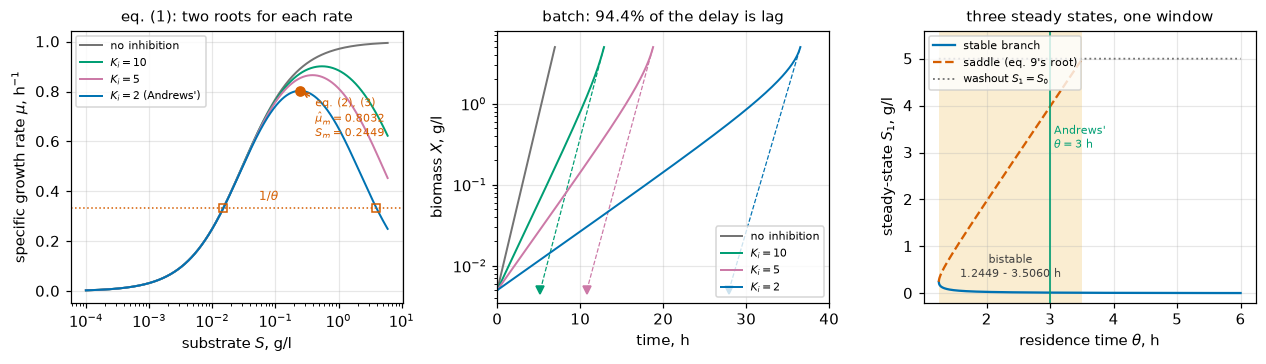

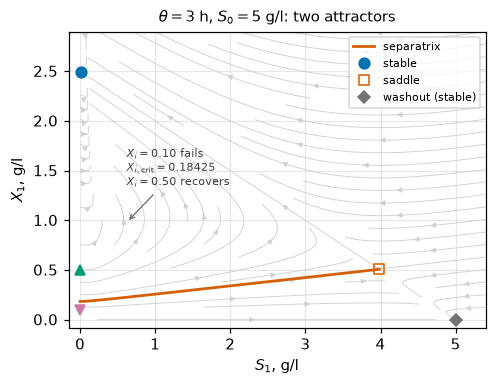

In [13]:
# ------------------------------------------------------------------- figures
fig, ax = plt.subplots(1, 3, figsize=(11.6, 3.4))

Sg = np.geomspace(1e-4, 6.0, 2000)
for Ki, c, lab in ((1e12, C_GREY, "no inhibition"), (10.0, C_GREEN, "$K_i=10$"),
                   (5.0, C_PURPLE, "$K_i=5$"), (K_I, C_BLUE, f"$K_i={K_I:g}$ (Andrews')")):
    ax[0].plot(Sg, mu(Sg, with_(Ki=Ki)), color=c, lw=1.3, label=lab)
ax[0].plot([S_M], [MU_HAT_M], "o", color=C_ORANGE, ms=6, zorder=5)
ax[0].annotate(f"eq. (2), (3)\n$\\hat\\mu_m={MU_HAT_M:.4f}$\n$S_m={S_M:.4f}$",
               (S_M, MU_HAT_M), xytext=(10, -30), textcoords="offset points",
               fontsize=7.5, color=C_ORANGE,
               arrowprops=dict(arrowstyle="->", color=C_ORANGE, lw=1))
ax[0].axhline(1/THETA, color=C_ORANGE, ls=":", lw=1)
ax[0].plot([S_LO, S_HI], [1/THETA, 1/THETA], "s", color=C_ORANGE, ms=5, mfc="none")
ax[0].text(0.055, 1/THETA + 0.03, r"$1/\theta$", fontsize=8, color=C_ORANGE)
ax[0].set_xscale("log")
ax[0].set_xlabel("substrate $S$, g/l")
ax[0].set_ylabel(r"specific growth rate $\mu$, h$^{-1}$")
ax[0].set_title("eq. (1): two roots for each rate", fontsize=9.5)
ax[0].legend(fontsize=7, loc="upper left")

for Ki, c, lab in ((1e12, C_GREY, "no inhibition"), (10.0, C_GREEN, "$K_i=10$"),
                   (5.0, C_PURPLE, "$K_i=5$"), (K_I, C_BLUE, f"$K_i={K_I:g}$")):
    Pk = with_(Ki=Ki)
    Xs = np.geomspace(X_INIT, X_TARGET, 400)
    ts = np.array([t_batch(X_INIT, x, S_INIT, Pk) for x in Xs])
    ax[1].plot(ts, Xs, color=c, lw=1.3, label=lab)
    r = lag_split(P0, Ki)
    if r["lag"] > 1e-9:
        tt = np.array([r["lag"], r["t_f"]])
        ax[1].plot(tt, X_INIT*np.exp(r["mu_max"]*(tt - r["lag"])), color=c, ls="--", lw=0.8)
        ax[1].plot([r["lag"]], [X_INIT], "v", color=c, ms=5)
ax[1].set_yscale("log")
ax[1].set_xlim(0, 40)
ax[1].set_ylim(X_INIT*0.7, 8)
ax[1].set_xlabel("time, h")
ax[1].set_ylabel("biomass $X$, g/l")
ax[1].set_title(f"batch: {BAT['lag_share_of_delay_Ki2']:.1%} of the delay is lag", fontsize=9.5)
ax[1].legend(fontsize=7, loc="lower right")

th = np.linspace(THETA_W*1.0000001, 6.0, 1200)
lo_b, hi_b = [], []
for t in th:
    ss = steady_states(with_(theta=t))
    lo_b.append(ss[0] if ss else np.nan)
    hi_b.append(ss[1] if len(ss) > 1 else np.nan)
ax[2].plot(th, lo_b, color=C_BLUE, lw=1.5, label="stable branch")
ax[2].plot(th, hi_b, color=C_ORANGE, lw=1.5, ls="--", label="saddle (eq. 9's root)")
ax[2].plot(th, np.full_like(th, S_FEED), color=C_GREY, lw=1.2, ls=":", label="washout $S_1=S_0$")
ax[2].axvspan(THETA_W, THETA_TRANS, color=C_YELLOW, alpha=0.18, lw=0)
ax[2].axvline(THETA, color=C_GREEN, lw=1.1)
ax[2].text(THETA + 0.06, 3.1, f"Andrews'\n$\\theta={THETA:g}$ h", fontsize=7.5, color=C_GREEN)
ax[2].text((THETA_W + THETA_TRANS)/2, 0.35, "bistable\n%.4f - %.4f h" % (THETA_W, THETA_TRANS),
           fontsize=7.5, ha="center", color="0.25")
ax[2].set_xlabel(r"residence time $\theta$, h")
ax[2].set_ylabel("steady-state $S_1$, g/l")
ax[2].set_ylim(-0.2, 5.6)
ax[2].set_title("three steady states, one window", fontsize=9.5)
ax[2].legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()

# phase plane: the separatrix and Andrews' two startup inocula
fig2, ax2 = plt.subplots(figsize=(4.6, 3.6))
Sq = np.linspace(1e-4, 5.4, 26)
Xq = np.linspace(1e-4, 2.9, 24)
SS_, XX_ = np.meshgrid(Sq, Xq)
M_ = mu(SS_, P0)
ax2.streamplot(Sq, Xq, (S_FEED - SS_)/THETA - M_*XX_/YIELD, -XX_/THETA + M_*XX_,
               color="0.82", density=0.8, linewidth=0.6, arrowsize=0.7)
sepS = np.linspace(0.0, S_HI - 1e-6, 220)
sepX = np.array([separatrix_X_at(float(s), S_FEED, P0) for s in sepS])
ax2.plot(sepS, sepX, color=C_ORANGE, lw=1.8, label="separatrix")
ax2.plot([S_LO], [X_LO], "o", color=C_BLUE, ms=7, label="stable")
ax2.plot([S_HI], [X_HI], "s", color=C_ORANGE, ms=7, mfc="none", label="saddle")
ax2.plot([S_FEED], [0.0], "D", color=C_GREY, ms=6, label="washout (stable)")
ax2.plot([S1_ZERO], [0.10], "v", color=C_PURPLE, ms=7)
ax2.plot([S1_ZERO], [0.50], "^", color=C_GREEN, ms=7)
ax2.annotate(f"$X_i=0.10$ fails\n$X_{{i,\\rm crit}}={X_CRIT:.5f}$\n$X_i=0.50$ recovers",
             (0.62, 0.98), fontsize=7.5, color="0.25",
             arrowprops=dict(arrowstyle="->", color="0.45", lw=0.9), xytext=(0.62, 1.35))
ax2.set_xlabel("$S_1$, g/l")
ax2.set_ylabel("$X_1$, g/l")
ax2.set_xlim(-0.15, 5.4)
ax2.set_ylim(-0.08, 2.9)
ax2.set_title(f"$\\theta={THETA:g}$ h, $S_0={S_FEED:g}$ g/l: two attractors", fontsize=9.5)
ax2.legend(fontsize=7, loc="upper right")
fig2.tight_layout()
plt.show()

## Validation

**Ranking.** There is no worked example with printed intermediates and there are
no measurements. The two highest available routes are used, and the fourth is
refused:

1. **Internal identities the paper must satisfy**: eqs. (2), (3), (6) and (11)
   re-derived from eq. (1) in sympy with residual exactly zero, eq. (9) checked
   against an independent root-find, and the stability of every steady state
   established from the sign of $\det J$ rather than from a picture.
2. **Stated numerical results in the text**: the two times of book p. 715, and
   the six stated outcomes of the three experiments on book p. 719.
3. **A digitised figure: refused.** Nothing on this page is traced, so **this
   page does not establish empirical adequacy against Andrews' plotted
   results**. Any claim that lives only in the shape of one of his curves is out
   of scope.

**Reproduction, not validation.** Everything in category 2 is Andrews' own
PACTOLUS output. Matching it says the equations were transcribed and integrated
correctly; it says nothing about whether microorganisms behave this way.

### Independent second computations

| quantity | route A | route B | what it can catch |
|---|---|---|---|
| batch time to the target | closed form (partial fractions, sympy-verified) | LSODA event | an error in either route |
| critical inoculum | root of the IVP outcome | saddle stable manifold, backward | an error in either route |
| critical step | root of the IVP outcome | separatrix side test | an error in either route |
| $X_0$ that removes the fold | root of the steady-state count, **grid-limited** | double root, $G = G' = 0$ | an error in either route |
| upper steady state | eq. (9) **as printed** | root of $\mu(S) = 1/\theta$ | **only a mis-transcription** |
| transcritical $\theta$ | $1/\mu(S_0)$, closed form | root of $S_+(\theta) = S_0$ | **only a mis-transcription** |
| chemostat transient | pymrm backward Euler + Richardson | LSODA | discretisation error |
| plug-flow outlet | pymrm steady solve + Richardson | batch IVP at $t = \tau$ | discretisation error |

**Four of those are second computations and two are transcription checks.**
eq. (9) *is* the quadratic the root-find solves, and $1/\mu(S_0)$ *is* eq. (9)
evaluated at $S_+ = S_0$, so those two agree to round-off by construction and the
only defect they can catch is a mis-transcribed equation; the break table injects
exactly that defect into each. The agreements are claims, printed with their
bounds in the cells above.

The last two rows are the refinement studies below. **Both axes that carry error
are refined**, the time step of the marcher and the grid of the plug-flow solve,
each with orders from successive differences of the refinement ladder
(`pymrm.checks.observed_orders`, no reference needed) and a round-off companion:
the finest successive difference must exceed the `newton` step tolerance, the
noise floor of a Newton-solved state, a thousandfold.

In [14]:
# ---- time-step refinement of the pymrm chemostat marcher -------------------
T_MARCH, C0_MARCH = 16.0, [0.0, 0.50]      # S_1(0) = 0, X_i = 0.50: Fig. 9's recovering case
NSTEPS = (150, 300, 600, 1200, 2400)
REF_MARCH = chemostat_ivp(C0_MARCH, T_MARCH, P0)


def march_study(P=P0, nsteps=NSTEPS, tol=NEWTON_TOL, dilution=True, theta_t=1.0):
    """Orders, Richardson error and round-off margin of the marcher on a step ladder."""
    vals = {n: ChemostatMarch(P, nstep=n, tol=tol, dilution=dilution, theta_t=theta_t)
            .march(C0_MARCH, T_MARCH)[0] for n in nsteps}
    orders = [o for k in (0, 1) for o in observed_orders(lambda n, k=k: vals[n][k], nsteps)["orders"]]
    rich = 2*vals[nsteps[-1]] - vals[nsteps[-2]]               # first order: Richardson
    diff = min(abs(vals[nsteps[-1]][k] - vals[nsteps[-2]][k]) for k in (0, 1))
    return dict(vals=vals, orders=orders,
                pymrm_march_time_step_order=max(orders, key=lambda p: abs(p - 1.0)),
                pymrm_march_richardson_abs_err=float(np.linalg.norm(rich - REF_MARCH)),
                finest_err=float(np.linalg.norm(vals[nsteps[-1]] - REF_MARCH)),
                pymrm_march_roundoff_margin=diff/tol)


MAR = march_study()
print(f"pymrm ChemostatMarch, t = {T_MARCH:g} h, LSODA reference (S {REF_MARCH[0]:.10f},"
      f" X {REF_MARCH[1]:.10f})")
for n, c in MAR["vals"].items():
    print(f"  nstep {n:5d}   S {c[0]:.10f}   X {c[1]:.10f}   |err| {np.linalg.norm(c - REF_MARCH):.6e}")
print(f"  observed orders (S then X): {[round(o, 4) for o in MAR['orders']]}")
print(f"  Richardson |err| {MAR['pymrm_march_richardson_abs_err']:.3e} against the finest"
      f" step's {MAR['finest_err']:.3e}; round-off margin {MAR['pymrm_march_roundoff_margin']:.1e}")

# ---- grid refinement of the pymrm plug-flow solve --------------------------
TAU_PFR, S_PFR = 3.0, S_FEED
NCELLS = (100, 200, 400, 800)
REF_PFR = batch_state(S_PFR, X_PFR, TAU_PFR, P0)


def pfr_study(P=P0, ncells=NCELLS, ratio=None, tol=NEWTON_TOL, **kw):
    """Orders, Richardson error, round-off margin and S + X/Y balance of the plug-flow solve."""
    sols = {n: PlugFlowFermenter(S_PFR, X_PFR, TAU_PFR, P, ncell=n, tol=tol, **kw).solve()
            for n in ncells}
    vals = {n: s.outlet() for n, s in sols.items()}
    orders = [o for k in (0, 1)
              for o in observed_orders(lambda n, k=k: vals[n][k], ncells, ratio)["orders"]]
    rich = 2*vals[ncells[-1]] - vals[ncells[-2]]
    diff = min(abs(vals[ncells[-1]][k] - vals[ncells[-2]][k]) for k in (0, 1))
    a = S_PFR + X_PFR/P["Y"]
    fine = sols[ncells[-1]].c
    return dict(vals=vals, orders=orders,
                pfr_outlet_grid_order=max(orders, key=lambda p: abs(p - 1.0)),
                pfr_richardson_abs_err=float(np.linalg.norm(rich - REF_PFR)),
                finest_err=float(np.linalg.norm(vals[ncells[-1]] - REF_PFR)),
                pfr_outlet_X_at_tau3_ncell800_g_per_l=float(vals[ncells[-1]][1]),
                pfr_roundoff_margin=diff/tol,
                pfr_cell_balance_max_rel=float(np.max(np.abs((fine[:, 0] + fine[:, 1]/P["Y"])/a - 1))))


PFR = pfr_study()
print(f"\npymrm PlugFlowFermenter outlet, tau = {TAU_PFR:g} h, batch reference"
      f" (S {REF_PFR[0]:.10f}, X {REF_PFR[1]:.10f})")
for n, o in PFR["vals"].items():
    print(f"  ncell {n:5d}   S {o[0]:.10f}   X {o[1]:.10f}   |err| {np.linalg.norm(o - REF_PFR):.6e}")
print(f"  observed orders (S then X): {[round(o, 4) for o in PFR['orders']]}")
print(f"  Richardson |err| {PFR['pfr_richardson_abs_err']:.3e} against the finest grid's"
      f" {PFR['finest_err']:.3e}; round-off margin {PFR['pfr_roundoff_margin']:.1e};"
      f" S + X/Y across the cells within {PFR['pfr_cell_balance_max_rel']:.0e}")

# ---- the tau = 6 h outlet, converged rather than taken off one grid ----------
TAU6 = 6.0
REF_TAU6 = batch_state(S_FEED, X_PFR, TAU6, P0)


def tau6_study(P=P0, **kw):
    """The tau = 6 h outlet biomass on 1200 and 2400 cells and their Richardson value."""
    o = {n: PlugFlowFermenter(S_FEED, X_PFR, TAU6, P, ncell=n, init="batch", **kw).solve().outlet()
         for n in (1200, 2400)}
    return dict(grid=float(o[1200][1]),
                pfr_outlet_X_at_tau6_richardson_g_per_l=float((2*o[2400] - o[1200])[1]))


T6 = tau6_study()
if abs(float(PFR_SWEEP[TAUS == TAU6, 1][0])/T6["grid"] - 1) > 1e-9:
    raise RuntimeError("the sweep's tau = 6 h entry is not the 1200-cell solve")

claims.bound("pymrm_march_time_step_order", MAR["pymrm_march_time_step_order"], min=0.95,
             max=1.05, basis="theory", note="backward Euler is first order; the value is the "
             "order furthest from 1 over both fields and every triple of the ladder")
claims.bound("pymrm_march_roundoff_margin", MAR["pymrm_march_roundoff_margin"], min=1e3,
             basis="chosen", note="finest successive difference over the newton step tolerance")
claims.value("pymrm_march_richardson_abs_err", MAR["pymrm_march_richardson_abs_err"], unit="g/l")
claims.bound("pfr_outlet_grid_order", PFR["pfr_outlet_grid_order"], min=0.95, max=1.05,
             basis="theory", note="first-order upwind; order furthest from 1 over both fields "
             "and every triple of the ladder")
claims.bound("pfr_roundoff_margin", PFR["pfr_roundoff_margin"], min=1e3, basis="chosen",
             note="finest successive difference over the newton step tolerance")
claims.value("pfr_richardson_abs_err", PFR["pfr_richardson_abs_err"], unit="g/l")
claims.value("pfr_outlet_X_at_tau3_ncell800_g_per_l", PFR["pfr_outlet_X_at_tau3_ncell800_g_per_l"],
             unit="g/l")
claims.value("pfr_outlet_X_at_tau6_richardson_g_per_l", T6["pfr_outlet_X_at_tau6_richardson_g_per_l"],
             unit="g/l")
claims.bound("pfr_cell_balance_max_rel", PFR["pfr_cell_balance_max_rel"], max=1e-9,
             basis="tolerance", structural=True,
             note="S + X/Y is carried unchanged by the yield-coupled source in every cell")

display(Markdown(
    f"**Marcher.** Observed orders from successive differences of the {len(NSTEPS)}-level step "
    f"ladder ({NSTEPS[0]} to {NSTEPS[-1]} steps over {T_MARCH:g} h) lie between "
    f"{min(MAR['orders']):.4f} and {max(MAR['orders']):.4f} (theory 1, bound 0.95 to 1.05); "
    f"Richardson brings the error against LSODA from {MAR['finest_err']:.2e} to "
    f"{MAR['pymrm_march_richardson_abs_err']:.2e} g/l, and the finest difference sits "
    f"{MAR['pymrm_march_roundoff_margin']:.0e} times above the `newton` tolerance.\n\n"
    f"**Plug flow.** Observed orders on {NCELLS[0]} to {NCELLS[-1]} cells lie between "
    f"{min(PFR['orders']):.4f} and {max(PFR['orders']):.4f} (first-order upwind, bound 0.95 to "
    f"1.05); Richardson brings the outlet error against the batch IVP from "
    f"{PFR['finest_err']:.2e} to {PFR['pfr_richardson_abs_err']:.2e} g/l. The outlet biomass on "
    f"{NCELLS[-1]} cells is {PFR['pfr_outlet_X_at_tau3_ncell800_g_per_l']:.7f} g/l, a grid value. The converged outlet is not "
    f"taken off a single grid: at $\\tau$ = {TAU6:g} h the 1200-cell value "
    f"{T6['grid']:.7f} g/l is {pct(T6['grid']/REF_TAU6[1] - 1)} from the batch reference "
    f"{REF_TAU6[1]:.8f} g/l, and the Richardson value of 1200 and 2400 cells, the one reported, "
    f"is {T6['pfr_outlet_X_at_tau6_richardson_g_per_l']:.7f} g/l."))

pymrm ChemostatMarch, t = 16 h, LSODA reference (S 0.0151457697, X 2.4827712151)
  nstep   150   S 0.0151544734   X 2.4818297490   |err| 9.415064e-04
  nstep   300   S 0.0151500703   X 2.4823058919   |err| 4.653431e-04
  nstep   600   S 0.0151479071   X 2.4825399112   |err| 2.313138e-04
  nstep  1200   S 0.0151468352   X 2.4826559032   |err| 1.153168e-04
  nstep  2400   S 0.0151463016   X 2.4827136443   |err| 5.757331e-05
  observed orders (S then X): [1.0254, 1.0129, 1.0065, 1.0248, 1.0126, 1.0064]
  Richardson |err| 1.702e-07 against the finest step's 5.757e-05; round-off margin 5.3e+04

pymrm PlugFlowFermenter outlet, tau = 3 h, batch reference (S 4.7224274718, X 0.2387862641)
  ncell   100   S 4.7204734307   X 0.2397632847   |err| 2.184684e-03
  ncell   200   S 4.7214546726   X 0.2392726637   |err| 1.087623e-03
  ncell   400   S 4.7219421202   X 0.2390289399   |err| 5.426397e-04
  ncell   800   S 4.7221850571   X 0.2389074715   |err| 2.710279e-04
  observed orders (S then X): [1.00

**Marcher.** Observed orders from successive differences of the 5-level step ladder (150 to 2400 steps over 16 h) lie between 1.0064 and 1.0254 (theory 1, bound 0.95 to 1.05); Richardson brings the error against LSODA from 5.76e-05 to 1.70e-07 g/l, and the finest difference sits 5e+04 times above the `newton` tolerance.

**Plug flow.** Observed orders on 100 to 800 cells lie between 1.0047 and 1.0094 (first-order upwind, bound 0.95 to 1.05); Richardson brings the outlet error against the batch IVP from 2.71e-04 to 5.84e-07 g/l. The outlet biomass on 800 cells is 0.2389075 g/l, a grid value. The converged outlet is not taken off a single grid: at $\tau$ = 6 h the 1200-cell value 0.6086422 g/l is +0.1637 % from the batch reference 0.60764725 g/l, and the Richardson value of 1200 and 2400 cells, the one reported, is 0.6076461 g/l.

### Break table

Every non-structural claim has a row below that injects a defect through an
argument or a constant of the study that computes it, recomputes the claim and
must fail its check. A row whose study cannot run records `nan` for the claims it
targets, and such a row catches nothing unless it is declared a detection by
failure. One row is: under the Monod limit $K_i \to 10^{12}$ g/l the upper steady
state does not exist, because eq. (9)'s second root $K_s K_i/S_-$ lies far above
the feed (section 5 prints it from the closed form), so the missing upper-branch
values are the detection. The $\hat\mu$ row moves the upper root by a finite amount
as well.

Two claims are structural and have no row: eq. (11) minus 1/eq. (2), which are
the same arithmetic expression, and the $S + X/Y$ balance across the plug-flow
cells, which the yield-coupled source enforces in every cell whatever the grid
or the kinetics.

**Four rows are transcription errors rather than physics errors.** Four claims,
eq. (2) and eq. (3) against their root-found values, eq. (9) against its root
and the transcritical residence time by its two routes, are zero by algebra
when the transcription is right, so mis-transcribing the equation is the only
thing that can move them; each has a row that mis-transcribes one term.

In [15]:
_MEMO = {}


def memo(tag, fn):
    """Run each study once per row argument set; a study that raised raises again."""
    if tag not in _MEMO:
        try:
            _MEMO[tag] = (True, fn())
        except Exception as exc:                 # noqa: BLE001 - a failed study is a result
            _MEMO[tag] = (False, exc)
    ok, v = _MEMO[tag]
    if not ok:
        raise v
    return v


def study(name, P=P0, **kw):
    fn = dict(inh=inhibition_study, bat=batch_study, tim=times_study, chem=chemostat_study,
              thr=threshold_study, six=six_outcomes, fold=fold_study, mar=march_study,
              pfr=pfr_study, t6=tau6_study)[name]
    return memo((name, _key(P), tuple(sorted(kw.items()))), lambda: fn(P, **kw))


def take(name, keys, P=P0, **kw):
    """{claim: study(...)[claim]} for the listed claims."""
    return {k: (lambda k=k: study(name, P, **kw)[k]) for k in keys}


def monotone(P=P0, **kw):
    b = study("bat", P, **kw)
    return bool(b["lag_share_of_delay_Ki10"] < b["lag_share_of_delay_Ki5"] < b["lag_share_of_delay_Ki2"])


INH_K = ["mu_hat_m_eq2_per_h", "S_m_eq3_g_per_l", "theta_washout_h", "rm_as_maximum_overstatement_rel",
         "half_rate_low_root_g_per_l", "half_rate_high_root_g_per_l", "Ks_definition_rel_error",
         "Ki_definition_rel_error"]
TIM_K = ["batch_time_direct_h", "batch_time_direct_vs_printed36_rel", "batch_time_seeded_h",
         "batch_time_seeded_vs_printed12p5_rel", "batch_time_seeded_reset_h",
         "batch_time_seeded_ladder_h", "seed_readings_raw_spread_rel", "seed_reset_vs_increment_rel",
         "seed_speedup_factor", "seed_first_cycle_h", "seed_rest_cycles_h", "seed_cycles"]
LAG_K = ["lag_hours_at_Ki2", "lag_share_of_delay_Ki2", "lag_expo_share_Ki2", "lag_share_of_delay_Ki5",
         "lag_share_of_delay_Ki10", "lag_share_of_delay_at_Xf1", "lag_share_of_delay_at_Xf0p5"]
CHEM_K = ["steady_S_lower_g_per_l", "steady_S_upper_g_per_l", "steady_X_lower_g_per_l",
          "steady_X_upper_g_per_l", "saddle_positive_eigenvalue_per_h",
          "washout_eigenvalue_haldane_per_h", "washout_eigenvalue_monod_per_h",
          "lower_node_fast_eigenvalue_per_h", "theta_transcritical_h", "monod_vs_haldane_S_shift_rel",
          "monod_vs_haldane_X_shift_rel", "monod_theta_c_h", "steady_state_kinds",
          "andrews_theta_inside_bistable_window"]
FOLD_K = ["feed_seed_fold_S_g_per_l", "feed_seed_removing_hysteresis_g_per_l",
          "feed_seed_share_of_operating_biomass"]


def thresholds(P):
    """The thresholds of section 6 at the constants P, each a separate root-find."""
    k = _key(P)
    return {"critical_inoculum_g_per_l": lambda: x_crit(k),
            "critical_step_S0_g_per_l": lambda: step_crit(k),
            "andrews_step_margin_rel": lambda: STEP_TO/step_crit(k) - 1,
            "critical_ramp_duration_h": lambda: ramp_crit(k),
            "andrews_ramp_margin_rel": lambda: RAMP_T/ramp_crit(k) - 1}


PM, PKS, PY4, PT4, PT12 = with_(Ki=1e12), with_(Ks=0.015), with_(Y=0.4), with_(theta=4.0), with_(theta=1.2)
PS7, PS3, PMU = with_(S0=7.0), with_(S0=3.0), with_(muh=0.9)
ROWS = [
    (f"K_i {K_I:g} -> 1e12 g/l (Monod)", {
        **take("inh", INH_K, PM), **take("tim", TIM_K, PM),
        **take("bat", ["batch_time_ratio_vs_no_inhibition", "lag_hours_at_Ki2", "peak_growth_rate_drop_rel",
                       "batch_realised_mean_growth_drop_rel", "peak_time_fraction",
                       "lag_biomass_fold_rise"], PM),
        **take("chem", CHEM_K, PM), **take("fold", FOLD_K, PM),
        "critical_inoculum_g_per_l": thresholds(PM)["critical_inoculum_g_per_l"],
        "all_six_stated_outcomes_ok": lambda: study("six", PM)["all_six_stated_outcomes_ok"]}),
    (f"K_s {K_S:g} -> 0.015 g/l", {
        **take("inh", INH_K + ["Ki_min_for_half_rate_defs_g_per_l", "Ks_definition_rel_error_Ki1",
                               "Ki_definition_rel_error_Ki1", "Ks_definition_rel_error_Ki0p5",
                               "Ki_definition_rel_error_Ki0p5"], PKS),
        **take("bat", ["branch_switch_Ki_g_per_l", "peak_growth_rate_drop_rel", "above_half_peak_fraction",
                       "lag_biomass_fold_rise", "batch_time_ratio_vs_no_inhibition"], PKS),
        **take("chem", CHEM_K, PKS), **take("fold", FOLD_K, PKS)}),
    (f"Y {YIELD:g} -> 0.4", {
        **take("chem", ["steady_X_lower_g_per_l", "steady_X_upper_g_per_l",
                        "lower_node_fast_eigenvalue_per_h"], PY4),
        "critical_inoculum_g_per_l": thresholds(PY4)["critical_inoculum_g_per_l"],
        **take("fold", ["feed_seed_removing_hysteresis_g_per_l"], PY4)}),
    ("operate at eq. (9)'s printed root", take(
        "chem", ["steady_S_lower_g_per_l", "steady_X_lower_g_per_l", "lower_node_fast_eigenvalue_per_h",
                 "monod_vs_haldane_S_shift_rel", "steady_state_kinds"], operate_at_eq9=True)),
    ("closed form with the (S_f - S_i)/K_i term dropped", take(
        "tim", ["batch_time_direct_h", "batch_time_direct_vs_printed36_rel",
                "batch_closedform_vs_lsoda_rel", "seed_speedup_factor"], drop_constant_term=True)),
    (f"theta {THETA:g} -> 4 h (above 1/mu(S_0))", {
        **take("six", ["all_six_stated_outcomes_ok", "fig8_direction_ok"], PT4),
        **take("chem", ["steady_state_kinds", "andrews_theta_inside_bistable_window",
                        "saddle_positive_eigenvalue_per_h", "steady_S_lower_g_per_l"], PT4),
        "critical_inoculum_g_per_l": thresholds(PT4)["critical_inoculum_g_per_l"],
        **take("fold", ["feed_seed_removing_hysteresis_g_per_l"], PT4)}),
    (f"theta {THETA:g} -> 1.2 h (below theta_w)", {
        **take("six", ["all_six_stated_outcomes_ok", "fig8_direction_ok"], PT12),
        **take("chem", ["steady_S_lower_g_per_l", "andrews_theta_inside_bistable_window"], PT12)}),
    (f"S_0 {S_FEED:g} -> 7 g/l (still bistable)", {
        **{k: v for k, v in thresholds(PS7).items() if "ramp" not in k}, **take("fold", FOLD_K, PS7),
        **take("chem", ["steady_X_lower_g_per_l", "steady_X_upper_g_per_l",
                        "washout_eigenvalue_haldane_per_h", "washout_eigenvalue_monod_per_h",
                        "theta_transcritical_h", "monod_theta_c_h"], PS7)}),
    (f"S_0 {S_FEED:g} -> 3 g/l (below the bistable range)", {
        **take("chem", ["theta_transcritical_h", "washout_eigenvalue_haldane_per_h",
                        "andrews_theta_inside_bistable_window"], PS3),
        "critical_inoculum_g_per_l": thresholds(PS3)["critical_inoculum_g_per_l"]}),
    (f"muhat {MU_HAT:g} -> 0.9 1/h", {
        **take("inh", ["mu_hat_m_eq2_per_h", "theta_washout_h"], PMU), **take("tim", TIM_K, PMU),
        **take("bat", ["batch_time_no_inhibition_h", "lag_hours_at_Ki2"], PMU), **thresholds(PMU),
        **take("chem", ["saddle_positive_eigenvalue_per_h", "steady_S_upper_g_per_l",
                        "washout_eigenvalue_haldane_per_h", "lower_node_fast_eigenvalue_per_h", "washout_eigenvalue_monod_per_h",
                        "monod_theta_c_h"], PMU)}),
    ("acclimation read as the 2/4/6 ladder", take(
        "tim", ["batch_time_seeded_h", "batch_time_seeded_vs_printed12p5_rel", "seed_speedup_factor",
                "seed_cycles", "seed_rest_cycles_h"], mode="ladder")),
    ("lag tangent at t = 0, not at the peak", {
        **take("bat", LAG_K, tangent="start"),
        "lag_share_monotone_in_Ki": lambda: monotone(tangent="start")}),
    ("marcher with the trapezoidal rule (theta_t = 1/2)", take(
        "mar", ["pymrm_march_time_step_order"], theta_t=0.5)),
    ("marcher with -c/theta dropped from the constant operator", take(
        "mar", ["pymrm_march_richardson_abs_err"], dilution=False)),
    ("marcher newton tolerance 1e-6", take("mar", ["pymrm_march_roundoff_margin"], tol=1e-6)),
    ("construct_div nu=1 (cylindrical)", {
        **take("pfr", ["pfr_outlet_X_at_tau3_ncell800_g_per_l", "pfr_richardson_abs_err"], nu=1),
        **take("t6", ["pfr_outlet_X_at_tau6_richardson_g_per_l"], nu=1)}),
    ("inlet bc zero-gradient, not Dirichlet", take(
        "pfr", ["pfr_outlet_X_at_tau3_ncell800_g_per_l", "pfr_richardson_abs_err"], inlet_bc="neumann")),
    ("plug-flow ladder 6/12/24/48 cells (not asymptotic)", take(
        "pfr", ["pfr_outlet_grid_order"], ncells=(6, 12, 24, 48))),
    ("plug-flow newton tolerance 1e-6", take("pfr", ["pfr_roundoff_margin"], tol=1e-6)),
    ("X_0 fold from the root count at ngrid 1501", take(
        "fold", ["feed_seed_fold_two_routes_rel"], ngrid=1501)),
    ("eq. (9) transcribed with 4 K_s K_i as 4 K_s", take(
        "chem", ["eq9_printed_vs_rootfound_upper_rel", "theta_transcritical_two_routes_rel"],
        eq9_disc_KsKi=False)),
    ("eq. (2) without the 2, eq. (3) without the square root", take(
        "inh", ["mu_hat_m_eq2_per_h", "S_m_eq3_g_per_l", "eq2_vs_rootfound_max_rel",
                "eq3_vs_rootfound_argmax_rel", "rm_as_maximum_overstatement_rel", "theta_washout_h"],
        eq2_factor=1.0, eq3_sqrt=False)),
    ("outcome classified at t = 50 h, not on an event", take(
        "thr", ["critical_inoculum_g_per_l", "critical_inoculum_two_routes_rel",
                "critical_inoculum_S1_init_sensitivity_rel",
                "critical_inoculum_S1_init_sensitivity_narrow_rel"], tend=50.0, event=False)),
    ("separatrix route B queried at the wrong substrate", {
        **take("thr", ["critical_inoculum_two_routes_rel"], query="operating"),
        "critical_step_two_routes_rel": lambda: abs(S0_STEP_CRIT/step_crit_separatrix(_key(P0), "S1") - 1)}),
    ("S_1(0) sensitivity over a sample without its largest value", take(
        "thr", ["critical_inoculum_S1_init_sensitivity_rel",
                "critical_inoculum_S1_init_sensitivity_narrow_rel"], sample=S1_SAMPLE[:-1])),
]

claims.define_rows([r[0] for r in ROWS])
# Under Monod there is no upper steady state (section 5: K_s K_i/S_- far above S_0),
# so the claims of the upper branch recording nan there is the detection.
BY_FAILURE = {(ROWS[0][0], k) for k in ("steady_S_upper_g_per_l", "steady_X_upper_g_per_l",
                                        "saddle_positive_eigenvalue_per_h")}
BREAK = []
for row, targets in ROWS:
    for name, fn in targets.items():
        try:
            out = fn()
        except Exception as exc:                 # noqa: BLE001 - a failed study is a result
            print(f"  {row}: {name} raised {type(exc).__name__}: {str(exc)[:80]}; records nan")
            out = np.nan
        caught_ = claims.breaks(row, name, out, detects_by_failure=(row, name) in BY_FAILURE)
        base_ = claims.metrics[name]["value"]
        if claims.metrics[name]["kind"] == "bound":   # round-off digits differ between machines
            base_ = f"(here {float(base_):.1e})"
            out = f"(here {float(out):.1e})" if isinstance(out, (int, float, np.floating)) else out
        elif isinstance(out, (float, np.floating)) and abs(out) < 1e-9:
            out = "below 1e-9"      # a defect that drives the state to zero, at round-off
        BREAK.append((row, name, base_, out, caught_))

bt = pd.DataFrame(BREAK, columns=["injected defect", "claim", "baseline", "with defect", "caught"])
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_rows", 400)
print(bt.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
idle = [r for r in bt["injected defect"].unique()
        if not bt[(bt["injected defect"] == r) & bt.caught].shape[0]]
print(f"\n{len(ROWS)} rows defined, {bt['injected defect'].nunique()} in the table; "
      f"rows that fail no claim: {idle or 'none'}")
missing = [k for k in claims.metrics if not claims.metrics[k].get("structural")
           and not bt[(bt.claim == k) & bt.caught].shape[0]]
print(f"claims no row fails: {missing or 'none'}")

  chemostat_study: transcritical theta: no sign change in the scanned range on [1, 50]
  K_i 2 -> 1e12 g/l (Monod): steady_S_upper_g_per_l raised KeyError: 'steady_S_upper_g_per_l'; records nan
  K_i 2 -> 1e12 g/l (Monod): steady_X_upper_g_per_l raised KeyError: 'steady_X_upper_g_per_l'; records nan
  K_i 2 -> 1e12 g/l (Monod): saddle_positive_eigenvalue_per_h raised KeyError: 'saddle_positive_eigenvalue_per_h'; records nan
  K_i 2 -> 1e12 g/l (Monod): feed_seed_fold_S_g_per_l raised RuntimeError: no upper limb below the feed: the fold does not exist; records nan
  K_i 2 -> 1e12 g/l (Monod): feed_seed_removing_hysteresis_g_per_l raised RuntimeError: no upper limb below the feed: the fold does not exist; records nan
  K_i 2 -> 1e12 g/l (Monod): feed_seed_share_of_operating_biomass raised RuntimeError: no upper limb below the feed: the fold does not exist; records nan


/home/eajfpeters/Code/pymrm_suite/worktrees/gallery-j42/pages/J4.2-andrews-substrate-inhibition/model.py:310: RuntimeWarning: invalid value encountered in scalar divide
  return dict(dtf=d, lag=(r["lag"] - b["lag"]) / d, expo=(r["expo"] - b["expo"]) / d,
/home/eajfpeters/Code/pymrm_suite/worktrees/gallery-j42/pages/J4.2-andrews-substrate-inhibition/model.py:311: RuntimeWarning: invalid value encountered in scalar divide
  tail=(r["tail"] - b["tail"]) / d)


  K_i 2 -> 1e12 g/l (Monod): critical_inoculum_g_per_l raised RuntimeError: critical inoculum: no sign change in the scanned range on [0.001, 2.5]; records nan


  theta 3 -> 4 h (above 1/mu(S_0)): saddle_positive_eigenvalue_per_h raised KeyError: 'saddle_positive_eigenvalue_per_h'; records nan


  theta 3 -> 4 h (above 1/mu(S_0)): critical_inoculum_g_per_l raised RuntimeError: critical inoculum: no sign change in the scanned range on [0.001, 2.5]; records nan
  theta 3 -> 4 h (above 1/mu(S_0)): feed_seed_removing_hysteresis_g_per_l raised RuntimeError: fold: no sign change in the scanned range on [0.244949, 5]; records nan
  theta 3 -> 1.2 h (below theta_w): steady_S_lower_g_per_l raised KeyError: 'steady_S_lower_g_per_l'; records nan


  S_0 5 -> 3 g/l (below the bistable range): critical_inoculum_g_per_l raised RuntimeError: critical inoculum: no sign change in the scanned range on [0.001, 1.5]; records nan


                                           injected defect                                            claim                       baseline                    with defect  caught
                                 K_i 2 -> 1e12 g/l (Monod)                               mu_hat_m_eq2_per_h                       0.803246                              1    True
                                 K_i 2 -> 1e12 g/l (Monod)                                  S_m_eq3_g_per_l                       0.244949                         173205    True
                                 K_i 2 -> 1e12 g/l (Monod)                                  theta_washout_h                        1.24495                              1    True
                                 K_i 2 -> 1e12 g/l (Monod)                  rm_as_maximum_overstatement_rel                       0.244949                     3.4641e-07    True
                                 K_i 2 -> 1e12 g/l (Monod)                       half_rate_low_root_g_per_l   

## What pymrm adds

**Not much to the 0-D physics, and something real to the question Andrews leaves
open.**

The batch and chemostat balances are two ODEs. pymrm's `NumJac` + `newton`
solves them, at first order in the step, and gets the same answer as LSODA;
that is a demonstration that the pymrm route is correct, not an improvement on
Andrews. The useful piece on the batch side is the closed form, which owes
nothing to pymrm either, and the thresholds come from `pymrm.checks.find_roots`
scans that refuse a range without exactly one root.

What pymrm does add is the **spatial** comparison of section 7:
`construct_convflux_upwind` + `construct_div` + `NumJac` + `newton`, with an
`{"outflow": True}` outlet read through `compute_boundary_values`, solve the
plug-flow limit of the *"multistage operation with separate substrate supply"*
that Andrews' Discussion lists as work in progress, and that reactor has no
bistability. This confirms his prediction **in that limit only**; a finite
cascade is not solved here and his other two modifications are untouched. The
seeded-feed result is likewise this page's, not Andrews', and needs no pymrm.

### Claims and the prose

The notebook's numbers are written by the code cells that compute them. The
numbers the README states are checked below against the claims they quote, so a
number in the text cannot drift from the computation and a cut in its precision
shows in CI (agreement.json "quoted"). Round-off-level results are quoted as
bounds.

In [16]:
SAYS = {   # README.md, meta.yaml and the models.yaml entry, literal for literal
    "batch_time_ratio_vs_no_inhibition": ["5.2564"], "lag_share_of_delay_Ki2": ["94.40 %"],
    "lag_expo_share_Ki2": ["5.65 %"], "lag_share_of_delay_Ki10": ["87.78 %"],
    "lag_share_of_delay_Ki5": ["91.25 %"], "peak_growth_rate_drop_rel": ["-19.43 %"],
    "peak_time_fraction": ["99.904 %"], "above_half_peak_fraction": ["1.7490 %"],
    "batch_realised_mean_growth_drop_rel": ["-80.98 %"], "lag_biomass_fold_rise": ["114.67"],
    "lag_share_of_delay_at_Xf1": ["109.4003 %"], "batch_time_direct_h": ["36.527476"],
    "batch_time_direct_vs_printed36_rel": ["+1.4652 %"], "batch_time_seeded_h": ["12.371597"],
    "batch_time_seeded_vs_printed12p5_rel": ["-1.0272 %"],
    "batch_closedform_vs_lsoda_rel": ["below 1e-9"], "seed_readings_raw_spread_rel": ["11.5442 %"],
    "seed_reset_vs_increment_rel": ["-0.0419 %"], "steady_S_lower_g_per_l": ["0.0150567"],
    "steady_X_lower_g_per_l": ["2.492472"], "lower_node_fast_eigenvalue_per_h": ["-73.019142"],
    "steady_S_upper_g_per_l": ["3.984943"], "steady_X_upper_g_per_l": ["0.507528"],
    "saddle_positive_eigenvalue_per_h": ["+0.0561790"],
    "washout_eigenvalue_haldane_per_h": ["-0.0481080"],
    "monod_vs_haldane_S_shift_rel": ["0.3778 %"], "monod_vs_haldane_X_shift_rel": ["-0.0011 %"],
    "washout_eigenvalue_monod_per_h": ["+0.660702"], "theta_washout_h": ["1.244949"],
    "theta_transcritical_h": ["3.506000"], "critical_inoculum_g_per_l": ["0.1842466"],
    "critical_inoculum_S1_init_sensitivity_rel": ["5.2120 %"],
    "critical_inoculum_S1_init_sensitivity_narrow_rel": ["0.4071 %"],
    "critical_step_S0_g_per_l": ["17.28760"], "critical_ramp_duration_h": ["0.8720668"],
    "andrews_ramp_margin_rel": ["14.67 %"], "critical_inoculum_two_routes_rel": ["below 1e-9"],
    "critical_step_two_routes_rel": ["below 1e-9"],
    "feed_seed_removing_hysteresis_g_per_l": ["0.0213935"],
    "feed_seed_share_of_operating_biomass": ["0.8583 %"],
    "feed_seed_fold_two_routes_rel": ["1.2e-9"],
    "pymrm_march_time_step_order": ["at least 0.95", "at most 1.05"],
    "pfr_outlet_grid_order": ["at least 0.95", "at most 1.05"],
    "pfr_outlet_X_at_tau6_richardson_g_per_l": ["0.6076461"],
    "half_rate_low_root_g_per_l": ["0.0304640"], "half_rate_high_root_g_per_l": ["1.969536"],
    "Ks_definition_rel_error": ["+1.5468 %"], "Ki_definition_rel_error": ["-1.5232 %"],
    "Ks_definition_rel_error_Ki1": ["+3.1947 %"], "Ki_definition_rel_error_Ki1": ["-3.0958 %"],
    "Ks_definition_rel_error_Ki0p5": ["+6.8502 %"], "Ki_definition_rel_error_Ki0p5": ["-6.4110 %"],
    "rm_as_maximum_overstatement_rel": ["24.4949 %"],
}
for _k, _lits in SAYS.items():
    for _lit in _lits:
        claims.says(_lit, _k)
print(f"prose literals: {sum(len(v) for v in SAYS.values())} checked against their claims with claims.says")
claims.report();   # the semicolon keeps the notebook from echoing the payload

prose literals: 55 checked against their claims with claims.says
Claims for J4.2:
  mu_hat_m_eq2_per_h                               = 0.80325          value  rtol 0.05
  S_m_eq3_g_per_l                                  = 0.24495          value  rtol 0.05
  theta_washout_h                                  = 1.2449           value  rtol 0.05
  eq2_vs_rootfound_max_rel                         = (here 0.0e+00)   bound  bound <= 1e-12 [tolerance]
  eq3_vs_rootfound_argmax_rel                      = (here 0.0e+00)   bound  bound <= 1e-12 [tolerance]
  eq11_minus_inverse_eq2                           = (here 0.0e+00)   bound  bound <= 1e-15 [identity]
  rm_as_maximum_overstatement_rel                  = 0.24495          value  rtol 0.05
  Ki_min_for_half_rate_defs_g_per_l                = 0.12             value  rtol 0.05
  half_rate_low_root_g_per_l                       = 0.030464         value  rtol 0.05
  half_rate_high_root_g_per_l                      = 1.9695           value  rtol 0.0

## Reuse

**Read $K_s$ and $K_i$ as the constants of eq. (1), not as the half-rate
concentrations they are named for.** They coincide only as $K_s/K_i \to 0$, and
how far out they are depends on the constants (the table in *Parameters*): quote
the error at *your* $K_i$, not at the mildest one. The naming has no meaning at
all unless $K_i \ge 4K_s$. If you are fitting the function, fit $\hat\mu$, $K_s$,
$K_i$; if you are reporting it, report $\hat\mu_m$ and $S_m$ from eqs. (2)-(3)
as well, because $\hat\mu$ alone is not a rate anything ever achieves.

**Do not carry a Monod textbook's definition of $r_m$ across to the inhibition
form.** Froment defines $r_m$ as *"the maximum specific rate of biomass growth"*
for eq. (1.5.2-1) and reuses the symbol in eq. (1.5.2-4), where the maximum is
$r_m/(1 + 2\sqrt{K_S/K_i})$.

**Use eq. (6)'s form, $\hat\mu S/(S^2/K_i + S + K_s)$, not eq. (1)'s.** They are
the same function, but eq. (1) is $0/0$-shaped at $S = 0$ and every batch and
startup calculation goes there.

**A chemostat on an inhibitory substrate has two washout conditions.** Andrews'
eq. (11), $\theta_w = \hat\mu_m^{-1}$, is the fold, and it has no $S_0$ in it. The
other, washout stable whenever $\mu(S_0) < 1/\theta$, depends on the feed, and it
is the one that produces bistability. Check both. Under Monod only the second
survives, as the $D_c = \mu_m S_f/(K_S + S_f)$ that J4.1 loads from Rawlings &
Ekerdt.

**A steady state that barely moves can still change character completely**
(section 5). Never conclude from *"the inhibition term is negligible at the
operating point"* that it is negligible.

**Root-find the thresholds; do not sweep for them**, on event-terminated
integrations, and compute the important ones a second way, as `model.fate` and
`model.separatrix_X_at` do here. A swept crossing would hide how narrowly
Andrews' ramp clears the critical one.

**Seed the feed if you can.** A small feed biomass removes the hysteresis
entirely (section 7), because washout stops being a steady state; this is this
page's extension, not Andrews'.

**And the batch lesson.** Inhibition on a batch culture shows up as lag, not as a
slower exponential phase, but do not report the peak slope as the growth rate,
and quote the target biomass with any lag share. Related pages: `J4.1` (Monod,
the rows this page borrows), and the plug-flow limit here is the batch problem of
section 1 in space.